## **1. Scrapping**

In [ ]:
!pip install google-play-scraper

In [ ]:
import os
import pandas as pd
from google_play_scraper import reviews, Sort

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
appId = 'com.netflix.mediaclient'
driveCsvPath = '/content/drive/MyDrive/TM/netflixReviews.csv'
csvPath = driveCsvPath if os.path.exists(driveCsvPath) else 'netflixReviews.csv'

def scrapeReviews():
    # scraping is turned off, this function is never called
    reviewList, _ = reviews(
        appId,
        lang='en',
        country='us',
        sort=Sort.NEWEST,
        count=5000
    )
    dfAll = pd.DataFrame(reviewList)
    dfData = dfAll[['content', 'score', 'at']].copy()
    dfData = dfData.dropna(subset=['content'])
    dfData = dfData.drop_duplicates(subset=['content'])
    dfData = dfData.sample(n=1000, random_state=42).reset_index(drop=True)
    dfData.to_csv(csvPath, index=False)
    return dfData

dfReviews = pd.read_csv(csvPath)

print(len(dfReviews))
print(dfReviews['score'].value_counts().sort_index())
dfReviews.head()

1000
score
1    133
2     38
3     52
4     93
5    684
Name: count, dtype: int64


,content,score,at
0,it's good,5,2026-10-18 17:08:21
1,I am so addicted to this 😫 😩,5,2026-10-26 10:26:59
2,Wonderful!!!! Well written. Acting is excellen...,5,2026-10-25 16:31:32
3,Why couldn't I watch Netflix in my Smart TV Sa...,5,2026-10-24 10:35:08
4,the pictures are clear the story telling is wo...,5,2026-10-18 20:32:15


## **2. EDA**
I explore the 1,000 scraped English reviews (columns: content, score for rating 1-5, and at for time) to understand the data before modelling.

In [ ]:
import re
import warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from IPython.display import display
from nltk.corpus import stopwords, wordnet, words
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud

warnings.filterwarnings('ignore')

for resourceName in ['stopwords', 'wordnet', 'words', 'vader_lexicon', 'omw-1.4']:
    nltk.download(resourceName, quiet=True)

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 120)

ratingOrder = [1, 2, 3, 4, 5]
ratingColors = {1: '#d62728', 2: '#ff7f0e', 3: '#bcbd22', 4: '#7fb97f', 5: '#2ca02c'}

### **Part 1: Data Overview and Rating Distribution**
I check the size, data types, missing values, duplicates, and how many reviews each rating has. A very large rating can bias the model.

In [ ]:
dfReviews = pd.read_csv(csvPath)
dfReviews['content'] = dfReviews['content'].astype(str)
dfReviews['at'] = pd.to_datetime(dfReviews['at'])

print('shape:', dfReviews.shape)
print()
print(dfReviews.dtypes)
print()
print('missing values:')
print(dfReviews.isnull().sum())
print()
print('duplicated reviews:', dfReviews['content'].duplicated().sum())
dfReviews.sample(8, random_state=1)

shape: (1000, 3)

content            object
score               int64
at         datetime64[ns]
dtype: object

missing values:
content    0
score      0
at         0
dtype: int64

duplicated reviews: 0


,content,score,at
507,just awesome.,5,2026-10-21 21:49:09
818,Netflix. me. liqhame,5,2026-10-27 16:53:38
452,"love your movies, u keep up with ""new ones!""",5,2026-10-21 01:19:29
368,"A wonderful movie - What is the price for ""Dignity"". People must watch it.",5,2026-10-18 11:00:42
242,it was a good movie.,4,2026-10-25 19:37:12
929,hey please dont remove this lively movie called letter to Juliet from netflix,5,2026-10-15 18:31:51
262,outstanding acting....well done production 👏,5,2026-10-17 11:32:08
810,all drama thing... pure cinema,5,2026-10-20 00:01:09


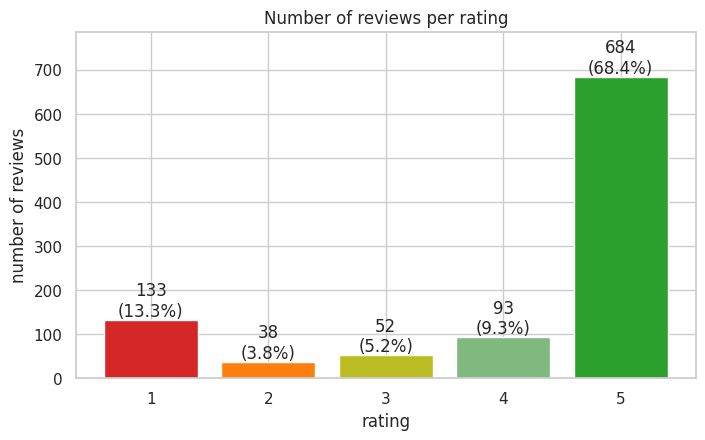

biggest class is 18.0 times bigger than the smallest class


In [ ]:
ratingCounts = dfReviews['score'].value_counts().reindex(ratingOrder, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(ratingCounts.index, ratingCounts.values, color=[ratingColors[r] for r in ratingCounts.index])
for bar, count in zip(bars, ratingCounts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
            f'{count}\n({count / len(dfReviews):.1%})', ha='center')
ax.set_xlabel('rating')
ax.set_ylabel('number of reviews')
ax.set_title('Number of reviews per rating')
ax.set_ylim(0, ratingCounts.max() * 1.15)
plt.show()

imbalanceRatio = ratingCounts.max() / ratingCounts.min()
print(f'biggest class is {imbalanceRatio:.1f} times bigger than the smallest class')

The data is imbalanced, rating 5 is the largest, rating 1 is second, and ratings 2 and 3 are very small. A model that always predicts 5 would look accurate, so I will use macro F1 and not accuracy alone, and I will handle the imbalance later.

### **Part 2: Review**
I check the period the reviews cover and whether the average rating changes over time.

first review: 2026-10-12 04:45:18
last review : 2026-10-28 17:22:11
days covered: 17


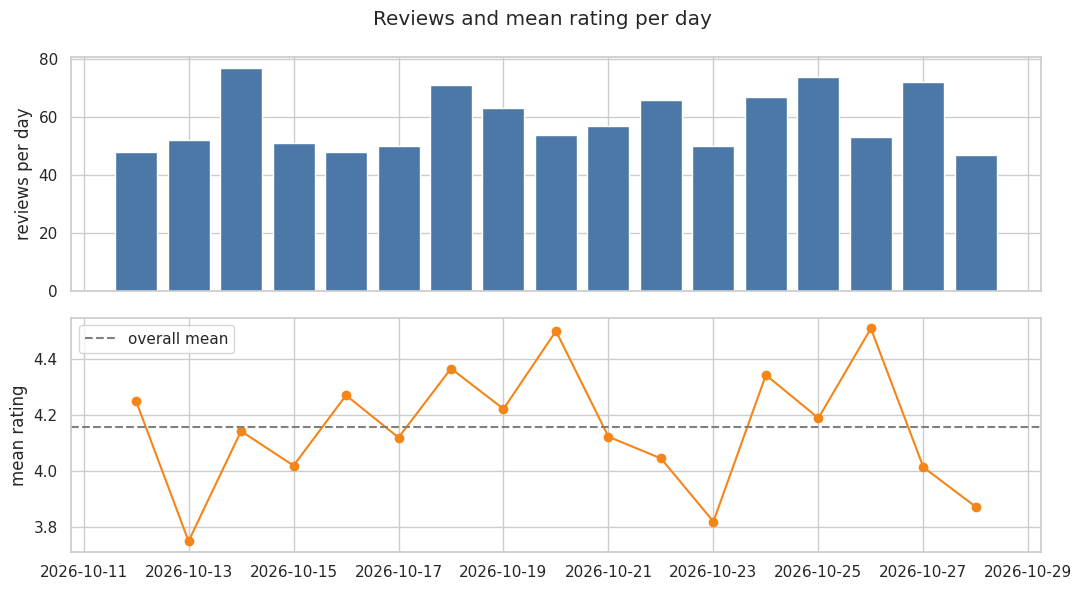

In [ ]:
print('first review:', dfReviews['at'].min())
print('last review :', dfReviews['at'].max())
print('days covered:', (dfReviews['at'].max() - dfReviews['at'].min()).days + 1)

dailyStats = dfReviews.set_index('at').resample('D')['score'].agg(['count', 'mean'])

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(dailyStats.index, dailyStats['count'], color='#4c78a8')
axes[0].set_ylabel('reviews per day')
axes[1].plot(dailyStats.index, dailyStats['mean'], marker='o', color='#f58518')
axes[1].axhline(dfReviews['score'].mean(), color='grey', linestyle='--', label='overall mean')
axes[1].set_ylabel('mean rating')
axes[1].legend()
fig.suptitle('Reviews and mean rating per day')
plt.tight_layout()
plt.show()

The reviews come from a short, recent period, so they describe the current app version. The mean rating moves a little, but the period is too short to call it a trend, so I will not use the date as a feature.

### **Part 3: Review Length**
I compare the number of characters and words between ratings.

charCount             wordCount            
           mean median  max      mean median  max
score                                            
1         117.3   79.0  500      21.3   15.0   93
2         112.3   66.5  437      22.1   10.5   99
3          84.3   54.5  499      16.2   10.0   89
4          58.2   38.0  493      11.4    7.0  100
5          53.9   27.0  481       9.9    5.0   91

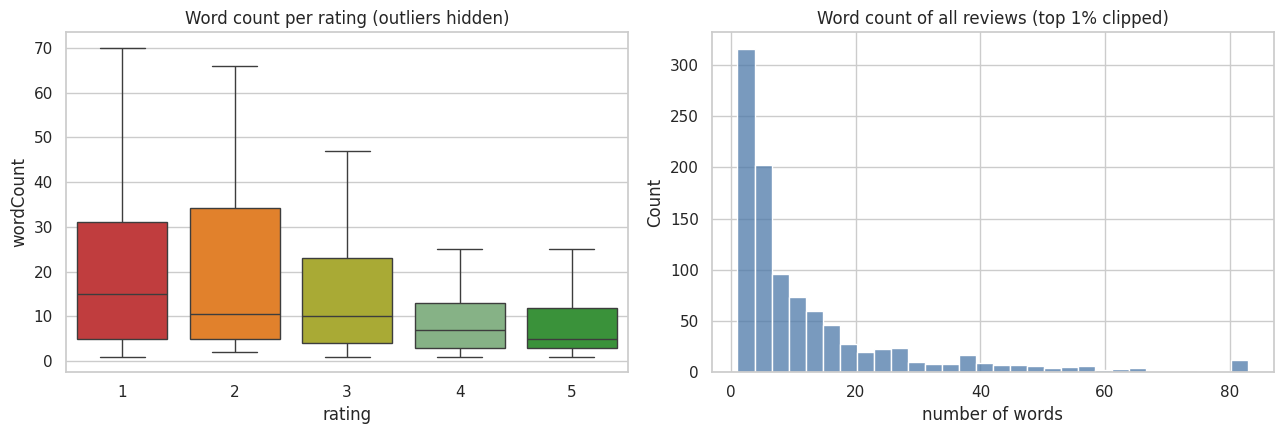

           score  wordCount
score      1.000     -0.231
wordCount -0.231      1.000


In [ ]:
dfReviews['charCount'] = dfReviews['content'].str.len()
dfReviews['wordCount'] = dfReviews['content'].str.split().str.len()

lengthSummary = dfReviews.groupby('score')[['charCount', 'wordCount']].agg(['mean', 'median', 'max']).round(1)
display(lengthSummary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=dfReviews, x='score', y='wordCount', hue='score', order=ratingOrder,
            palette=ratingColors, showfliers=False, legend=False, ax=axes[0])
axes[0].set_title('Word count per rating (outliers hidden)')
axes[0].set_xlabel('rating')

clipLimit = dfReviews['wordCount'].quantile(0.99)
sns.histplot(dfReviews['wordCount'].clip(upper=clipLimit), bins=30, color='#4c78a8', ax=axes[1])
axes[1].set_title('Word count of all reviews (top 1% clipped)')
axes[1].set_xlabel('number of words')
plt.tight_layout()
plt.show()

print(dfReviews[['score', 'wordCount']].corr(method='spearman').round(3))

In [ ]:
dfReviews['isShort'] = dfReviews['wordCount'] <= 3
shortShareByRating = (dfReviews.groupby('score')['isShort'].mean() * 100).round(1)

print('Reviews with 3 words or fewer:', dfReviews['isShort'].sum(), f'({dfReviews["isShort"].mean():.1%})')
print()
print('Share of short reviews in each rating (%):')
print(shortShareByRating)
print()
print('Longest review has', dfReviews['wordCount'].max(), 'words')

Reviews with 3 words or fewer: 316 (31.6%)

Share of short reviews in each rating (%):
score
1    19.5
2    13.2
3    21.2
4    30.1
5    36.0
Name: isShort, dtype: float64

Longest review has 100 words


Most reviews are short, and a few long ones raise the average, so the median is more useful. Low ratings are longer, because unhappy users explain their problem, while high ratings are often one word like "good". Length carries some information, but very short reviews give the model little to learn from.

### **Part 4: Writing Style**
I compare, between ratings, the average number of exclamation marks, emojis, capital letter share, stretched letters (like "sooo"), and digits.

In [ ]:
emojiPattern = re.compile('[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F000-\U0001F2FF]')

def getUpperRatio(text):
    letters = [char for char in text if char.isalpha()]
    if not letters:
        return 0.0
    return sum(char.isupper() for char in letters) / len(letters)

dfReviews['exclamationCount'] = dfReviews['content'].str.count('!')
dfReviews['emojiCount'] = dfReviews['content'].apply(lambda text: len(emojiPattern.findall(text)))
dfReviews['upperRatio'] = dfReviews['content'].apply(getUpperRatio)
dfReviews['hasStretched'] = dfReviews['content'].str.contains(r'([a-zA-Z])\1{2,}', regex=True)
dfReviews['hasDigit'] = dfReviews['content'].str.contains(r'\d', regex=True)

styleSummary = dfReviews.groupby('score').agg(
    meanExclamations=('exclamationCount', 'mean'),
    meanEmojis=('emojiCount', 'mean'),
    pctWithEmoji=('emojiCount', lambda s: (s > 0).mean() * 100),
    meanUpperRatio=('upperRatio', 'mean'),
    pctStretched=('hasStretched', lambda s: s.mean() * 100),
    pctWithDigit=('hasDigit', lambda s: s.mean() * 100),
)
styleSummary.round(2).style.background_gradient(cmap='Blues', axis=0)

,meanExclamations,meanEmojis,pctWithEmoji,meanUpperRatio,pctStretched,pctWithDigit
score,,,,,,
1,0.140000,0.220000,11.280000,0.050000,2.260000,15.790000
2,0.080000,0.110000,7.890000,0.030000,5.260000,15.790000
3,0.020000,0.170000,13.460000,0.030000,0.000000,5.770000
4,0.050000,0.320000,18.280000,0.030000,4.300000,4.300000
5,0.160000,0.610000,23.540000,0.060000,1.170000,5.850000


Emojis, exclamation marks, and stretched letters differ between ratings, so they carry feeling and are not just noise. I should not delete all punctuation and emojis in preprocessing.

### **Part 5: Light Cleaning for Exploration**
For fair word counts I make a simple clean version (not the final preprocessing): lowercase, fix apostrophes, remove links, keep letters and apostrophes, and split into tokens. I make three lists:
- tokens: all words
- tokensNoStop: no stopwords and no one-letter words
- tokensKeepNeg: no stopwords, but I keep negations ("not", "no", "don't"), because "not working" and "working" have opposite meanings

In [ ]:
stopWords = set(stopwords.words('english'))
negationWords = {word for word in stopWords if word in ('no', 'not', 'nor') or word.endswith("n't")}

def cleanForEda(text):
    text = text.lower()
    text = text.replace('\u2019', "'")
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r"[^a-z'\s]", ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def tokenize(text):
    return [token.strip("'") for token in text.split() if token.strip("'")]

dfReviews['cleanText'] = dfReviews['content'].apply(cleanForEda)
dfReviews['tokens'] = dfReviews['cleanText'].apply(tokenize)
dfReviews['tokensNoStop'] = dfReviews['tokens'].apply(
    lambda tokenList: [t for t in tokenList if t not in stopWords and len(t) > 1])
dfReviews['tokensKeepNeg'] = dfReviews['tokens'].apply(
    lambda tokenList: [t for t in tokenList if (t not in stopWords or t in negationWords) and len(t) > 1])

dfReviews[['content', 'cleanText', 'tokensNoStop']].head(5)

,content,cleanText,tokensNoStop
0,it's good,it's good,[good]
1,I am so addicted to this 😫 😩,i am so addicted to this,[addicted]
2,Wonderful!!!! Well written. Acting is excellent! I cried on all episodes!,wonderful well written acting is excellent i cried on all episodes,"[wonderful, well, written, acting, excellent, cried, episodes]"
3,Why couldn't I watch Netflix in my Smart TV Samsung 65 anymore Why couldn't I watch Netflix on my Smart TV i.e. Sams...,why couldn't i watch netflix in my smart tv samsung anymore why couldn't i watch netflix on my smart tv i e samsung ...,"[watch, netflix, smart, tv, samsung, anymore, watch, netflix, smart, tv, samsung, anymore]"
4,the pictures are clear the story telling is wow they cooked here I'm so loving this one 😍,the pictures are clear the story telling is wow they cooked here i'm so loving this one,"[pictures, clear, story, telling, wow, cooked, loving, one]"


### **Part 6: The Effect of Stopwords**
I compare the most common words before and after removing stopwords ("the", "is", "and").

total words: 11992
unique words: 2445
share of words that are stopwords: 42.6%


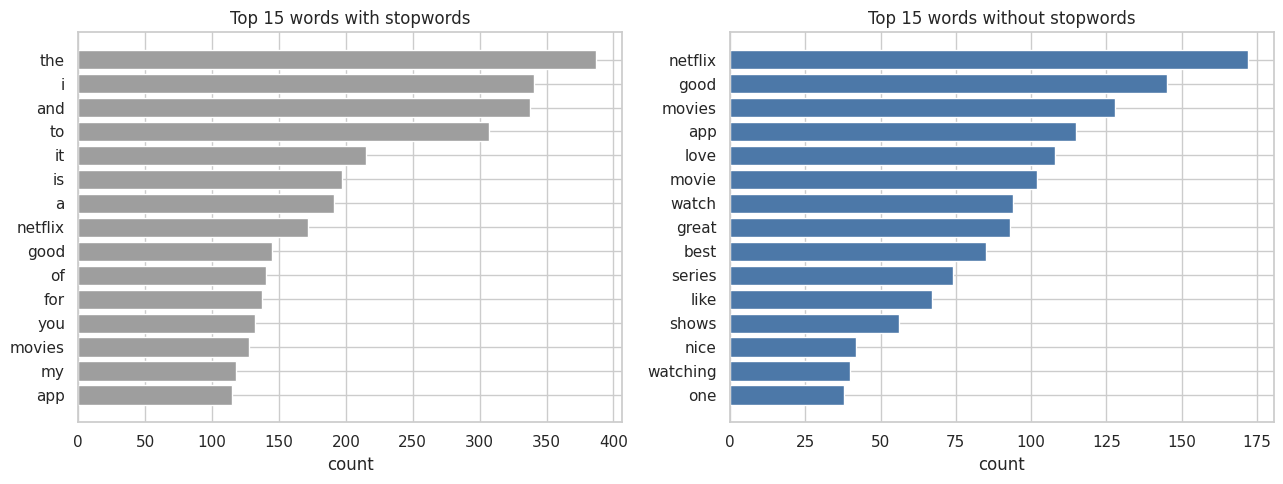

In [ ]:
def drawBar(ax, pairs, title, color):
    labels = [pair[0] for pair in pairs][::-1]
    values = [pair[1] for pair in pairs][::-1]
    ax.barh(labels, values, color=color)
    ax.set_title(title)

allTokens = [token for tokenList in dfReviews['tokens'] for token in tokenList]
rawTop = Counter(allTokens).most_common(15)
noStopTop = Counter(t for tokenList in dfReviews['tokensNoStop'] for t in tokenList).most_common(15)
stopShare = sum(token in stopWords for token in allTokens) / len(allTokens)

print('total words:', len(allTokens))
print('unique words:', len(set(allTokens)))
print(f'share of words that are stopwords: {stopShare:.1%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
drawBar(axes[0], rawTop, 'Top 15 words with stopwords', '#9e9e9e')
drawBar(axes[1], noStopTop, 'Top 15 words without stopwords', '#4c78a8')
for ax in axes:
    ax.set_xlabel('count')
plt.tight_layout()
plt.show()

With stopwords, the top words say nothing about the app. Without them, real topics appear (app, shows, movies). But negations like "not" and "no" change the meaning, so I must keep them.

### **Part 7: Dominant Words in Each Rating**
The ratings have different sizes, so I use the percentage of reviews in a rating that contain the word, not raw counts. I show a table, bar charts, and word clouds for low (1-2) and high (4-5) ratings.

In [ ]:
def topDocFreq(tokenLists, topN=10):
    docFreq = Counter()
    for tokenList in tokenLists:
        docFreq.update(set(tokenList))
    total = len(tokenLists)
    return [(word, count / total) for word, count in docFreq.most_common(topN)]

topWordsByRating = {
    rating: topDocFreq(dfReviews.loc[dfReviews['score'] == rating, 'tokensNoStop'].tolist(), 10)
    for rating in ratingOrder
}

topWordsTable = pd.DataFrame({
    f'rating {rating}': [f'{word} ({share:.0%})' for word, share in topWordsByRating[rating]]
    for rating in ratingOrder
})
topWordsTable.index = range(1, 11)
topWordsTable

,rating 1,rating 2,rating 3,rating 4,rating 5
1,netflix (23%),movies (21%),movies (19%),good (16%),good (16%)
2,app (20%),get (13%),app (15%),like (12%),netflix (15%)
3,use (10%),watch (13%),good (15%),app (11%),love (14%)
4,even (9%),app (13%),watch (13%),best (11%),great (12%)
5,get (8%),netflix (13%),series (12%),movies (10%),movies (11%)
6,watch (8%),series (11%),even (10%),movie (10%),movie (11%)
7,can't (8%),want (11%),get (8%),nice (9%),best (10%)
8,account (8%),every (11%),like (8%),netflix (6%),watch (8%)
9,money (7%),keeps (8%),many (8%),love (6%),app (8%)
10,like (6%),something (8%),enough (8%),shows (6%),series (7%)


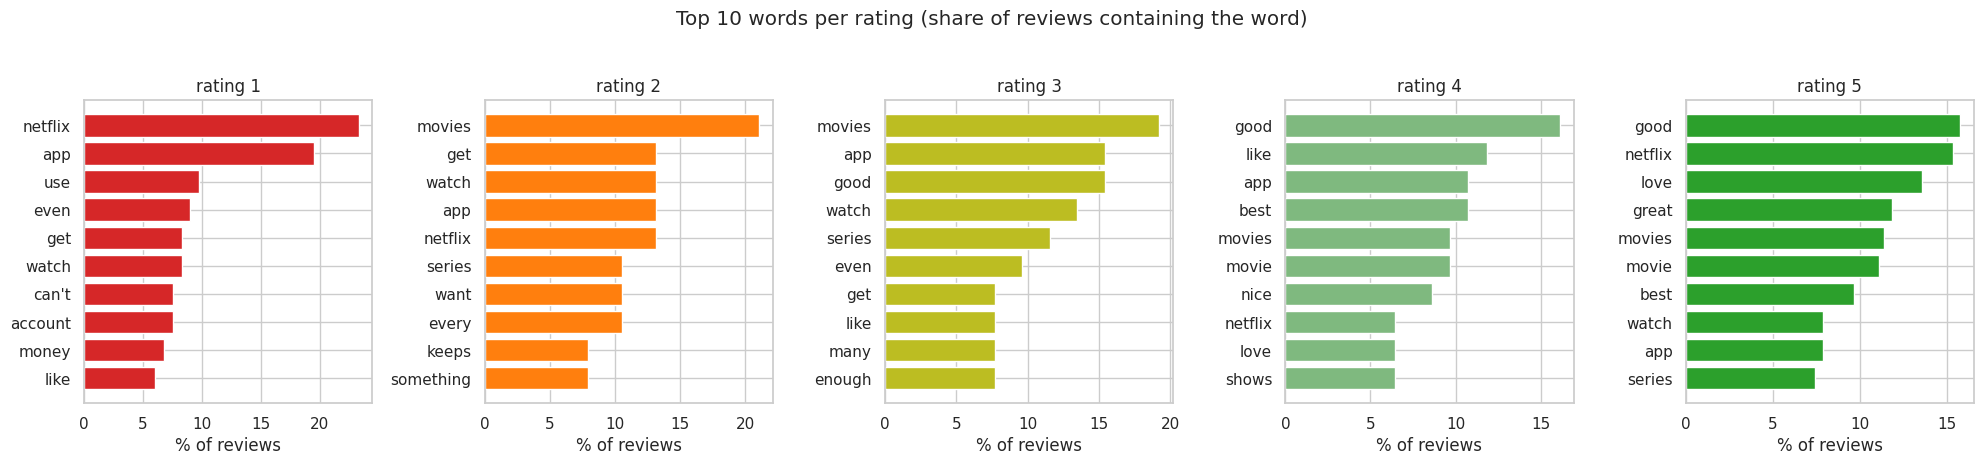

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, rating in zip(axes, ratingOrder):
    pairs = [(word, share * 100) for word, share in topWordsByRating[rating]]
    drawBar(ax, pairs, f'rating {rating}', ratingColors[rating])
    ax.set_xlabel('% of reviews')
plt.suptitle('Top 10 words per rating (share of reviews containing the word)', y=1.03)
plt.tight_layout()
plt.show()

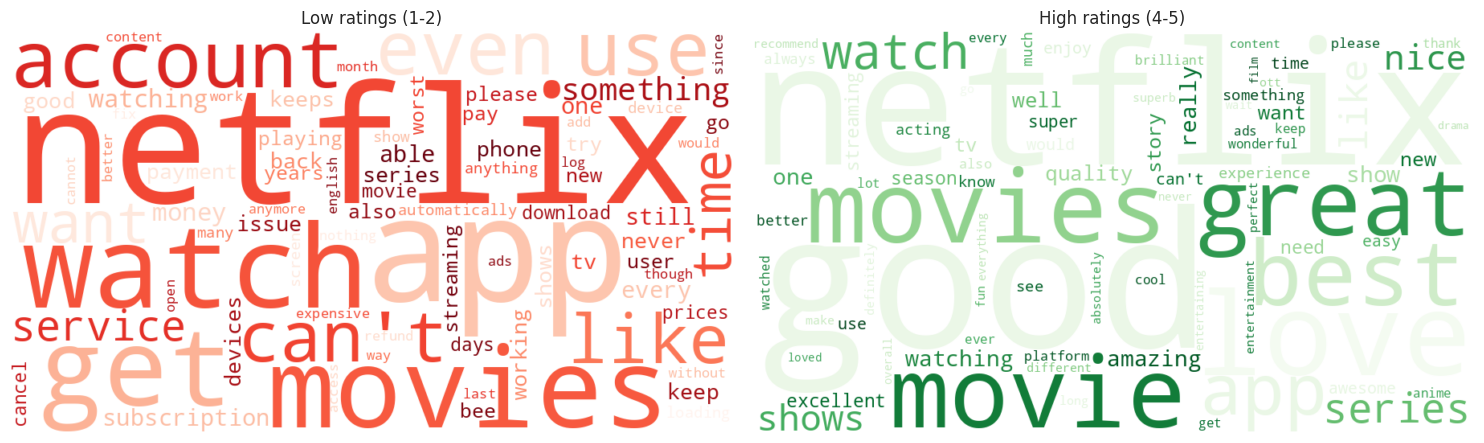

In [ ]:
def drawCloud(ax, tokenLists, title, colormap):
    freq = Counter(token for tokenList in tokenLists for token in tokenList)
    cloud = WordCloud(width=900, height=500, background_color='white', colormap=colormap,
                      max_words=80, random_state=42).generate_from_frequencies(freq)
    ax.imshow(cloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
drawCloud(axes[0], dfReviews.loc[dfReviews['score'] <= 2, 'tokensNoStop'], 'Low ratings (1-2)', 'Reds')
drawCloud(axes[1], dfReviews.loc[dfReviews['score'] >= 4, 'tokensNoStop'], 'High ratings (4-5)', 'Greens')
plt.tight_layout()
plt.show()

Many top words are shared by all ratings ("netflix", "app", "movies", "watch", "get"), so they describe the topic, not the feeling. The differences are small but clear: rating 1 has problem words ("can't", "account", "money"), and ratings 4-5 have praise words ("good", "love", "best", "great", "nice"). Ratings 2 and 3 show no clear pattern because they have few reviews.

### **Part 8: Common Phrases (Bigrams and Trigrams)**
Phrases keep context: "not working" is a complaint, but "working" is neutral. I group the reviews into low, neutral, and high, because ratings 2 and 3 are too small alone.

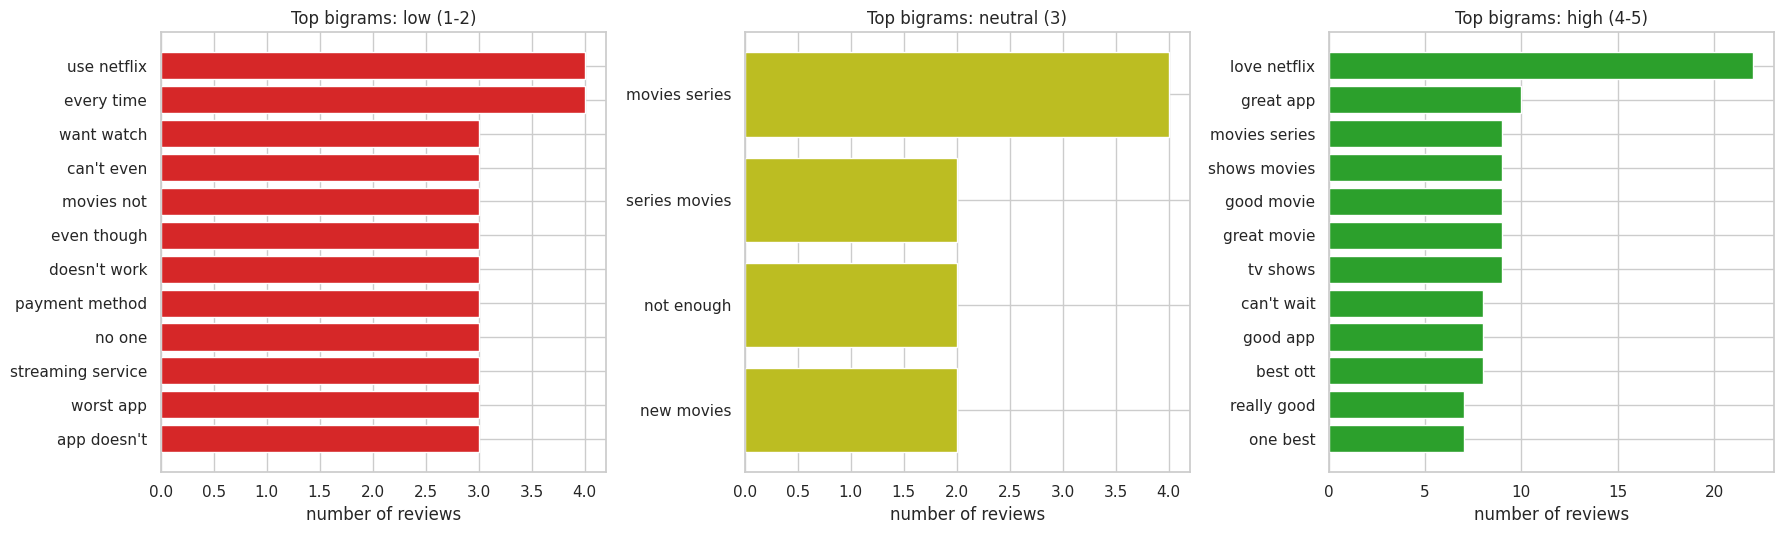

top trigrams, low (1-2)
   wrong please try: 2
   went wrong please: 2
   something went wrong: 2
   shows something went: 2
   even use netflix: 2
   can't even use: 2

top trigrams, neutral (3)

top trigrams, high (4-5)
   movies tv shows: 5
   offers wide variety: 3
   wide variety movies: 3
   movies want watch: 3
   app watch movies: 3
   movies series documentaries: 3
   something interesting watch: 3
   best ott platform: 3



In [ ]:
dfReviews['textForNgram'] = dfReviews['tokensKeepNeg'].apply(' '.join)

ratingGroups = {
    'low (1-2)': dfReviews['score'] <= 2,
    'neutral (3)': dfReviews['score'] == 3,
    'high (4-5)': dfReviews['score'] >= 4,
}
groupColors = ['#d62728', '#bcbd22', '#2ca02c']

def topNgrams(texts, ngramRange, topN=12):
    vectorizer = CountVectorizer(ngram_range=ngramRange, tokenizer=str.split, token_pattern=None,
                                 lowercase=False, binary=True, min_df=2)
    try:
        matrix = vectorizer.fit_transform(texts)
    except ValueError:
        return []
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    names = vectorizer.get_feature_names_out()
    order = counts.argsort()[::-1][:topN]
    return [(names[i], int(counts[i])) for i in order]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (groupName, mask), color in zip(axes, ratingGroups.items(), groupColors):
    pairs = topNgrams(dfReviews.loc[mask, 'textForNgram'], (2, 2))
    drawBar(ax, pairs, f'Top bigrams: {groupName}', color)
    ax.set_xlabel('number of reviews')
plt.tight_layout()
plt.show()

for groupName, mask in ratingGroups.items():
    print(f'top trigrams, {groupName}')
    for phrase, count in topNgrams(dfReviews.loc[mask, 'textForNgram'], (3, 3), 8):
        print(f'   {phrase}: {count}')
    print()

Phrases show the reasons for the ratings better than single words. Low-rating phrases are about problems and often include "not" or "can't", and high-rating phrases are short praise. If I removed "not" as a stopword, "not working" would become "working", so I will keep negations.

### **Part 9: Words That Separate Low and High Ratings**
For words that appear at least 8 times, I compare their use in low (1-2) and high (4-5) ratings with a log ratio. A positive value means the word belongs more to low ratings, and a negative value means high ratings.

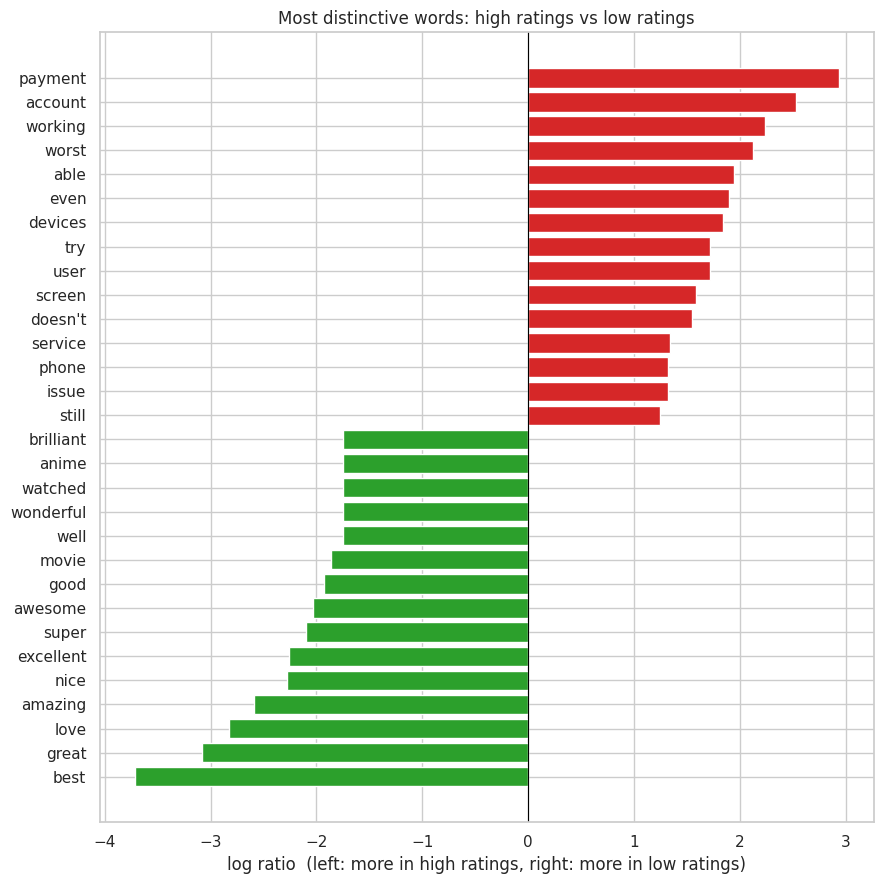

In [ ]:
lowCounter = Counter(t for tokenList in dfReviews.loc[dfReviews['score'] <= 2, 'tokensKeepNeg'] for t in tokenList)
highCounter = Counter(t for tokenList in dfReviews.loc[dfReviews['score'] >= 4, 'tokensKeepNeg'] for t in tokenList)

vocab = [word for word in set(lowCounter) | set(highCounter) if lowCounter[word] + highCounter[word] >= 8]
lowTotal = sum(lowCounter.values())
highTotal = sum(highCounter.values())

logRatio = {
    word: np.log((lowCounter[word] + 1) / (lowTotal + len(vocab)))
          - np.log((highCounter[word] + 1) / (highTotal + len(vocab)))
    for word in vocab
}

ranked = sorted(logRatio.items(), key=lambda item: item[1])
plotItems = ranked[:15] + ranked[-15:]
plotWords = [item[0] for item in plotItems]
plotValues = [item[1] for item in plotItems]
plotColors = ['#2ca02c' if value < 0 else '#d62728' for value in plotValues]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(plotWords, plotValues, color=plotColors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('log ratio  (left: more in high ratings, right: more in low ratings)')
ax.set_title('Most distinctive words: high ratings vs low ratings')
plt.tight_layout()
plt.show()

Green words (left) are praise words typical for 4-5 stars. Red words (right) show the reasons for bad ratings: account, payment, and the app not working. These are good clues for the model, and they are often not the most frequent words.

### **Part 10: Non-Standard Words**
The task asks whether non-standard words are frequent. A word is "standard" if it is a stopword, in the NLTK word list, known by WordNet, or a known brand or device name (like "netflix"). Everything else is non-standard, and I group it as:
- missing apostrophe: "dont", "cant"
- stretched letters: "sooo", "goood"
- single letter: "u", "r"
- other: typos, slang ("pls"), names, other languages bold text

In [ ]:
englishVocab = {word.lower() for word in words.words()}
brandTerms = {'netflix', 'youtube', 'disney', 'hulu', 'hbo', 'amazon', 'prime', 'samsung', 'roku',
              'chromecast', 'android', 'iphone', 'ios', 'wifi', 'tv', 'hd', 'ui', 'ipad', 'google',
              'app', 'apps', 'ott', 'vpn', 'anytime', 'etc', 'others'}

@lru_cache(maxsize=None)
def isStandardWord(word):
    if len(word) == 1:
        return word in ('a', 'i')
    if word in stopWords or word in englishVocab or word in brandTerms:
        return True
    if "'" in word:
        return isStandardWord(word.split("'")[0])
    return len(wordnet.synsets(word)) > 0

noApostropheForms = {word.replace("'", '') for word in stopWords if "'" in word} | {'im', 'ive', 'cant', 'theyre', 'weve'}

def categorizeWord(word):
    if len(word) == 1:
        return 'single letter'
    if word in noApostropheForms:
        return 'missing apostrophe'
    if re.search(r'(.)\1{2,}', word):
        return 'stretched letters'
    return 'other (typo, slang, name, other language)'

tokenCounter = Counter(allTokens)
nonStandardCounter = Counter({w: c for w, c in tokenCounter.items() if not isStandardWord(w)})

totalTokens = len(allTokens)
nonStandardTokens = sum(nonStandardCounter.values())
reviewsWithNonStandard = dfReviews['tokens'].apply(lambda tokenList: any(t in nonStandardCounter for t in tokenList)).mean()

print('Unique non-standard words:', len(nonStandardCounter), 'of', len(tokenCounter), 'unique words')
print(f'Non-standard words in all text: {nonStandardTokens} of {totalTokens} ({nonStandardTokens / totalTokens:.1%})')
print(f'Reviews with at least one non-standard word: {reviewsWithNonStandard:.1%}')

Unique non-standard words: 415 of 2445 unique words
Non-standard words in all text: 604 of 11992 (5.0%)
Reviews with at least one non-standard word: 21.5%


In [ ]:
nonStandardTable = pd.DataFrame(
    [(word, count, categorizeWord(word)) for word, count in nonStandardCounter.items()],
    columns=['word', 'count', 'category']
)

categorySummary = (nonStandardTable.groupby('category')
                   .agg(uniqueWords=('word', 'count'), totalCount=('count', 'sum'))
                   .sort_values('totalCount', ascending=False))
display(categorySummary)

print('top 25 non-standard words:')
display(nonStandardTable.sort_values('count', ascending=False).head(25).reset_index(drop=True))

,uniqueWords,totalCount
category,,
"other (typo, slang, name, other language)",372,447
single letter,20,131
stretched letters,21,24
missing apostrophe,2,2


top 25 non-standard words:


,word,count,category
0,f,36,single letter
1,u,17,single letter
2,s,12,single letter
3,e,11,single letter
4,o,8,single letter
5,pls,8,"other (typo, slang, name, other language)"
6,t,6,single letter
7,c,6,single letter
8,que,6,"other (typo, slang, name, other language)"
9,d,5,single letter


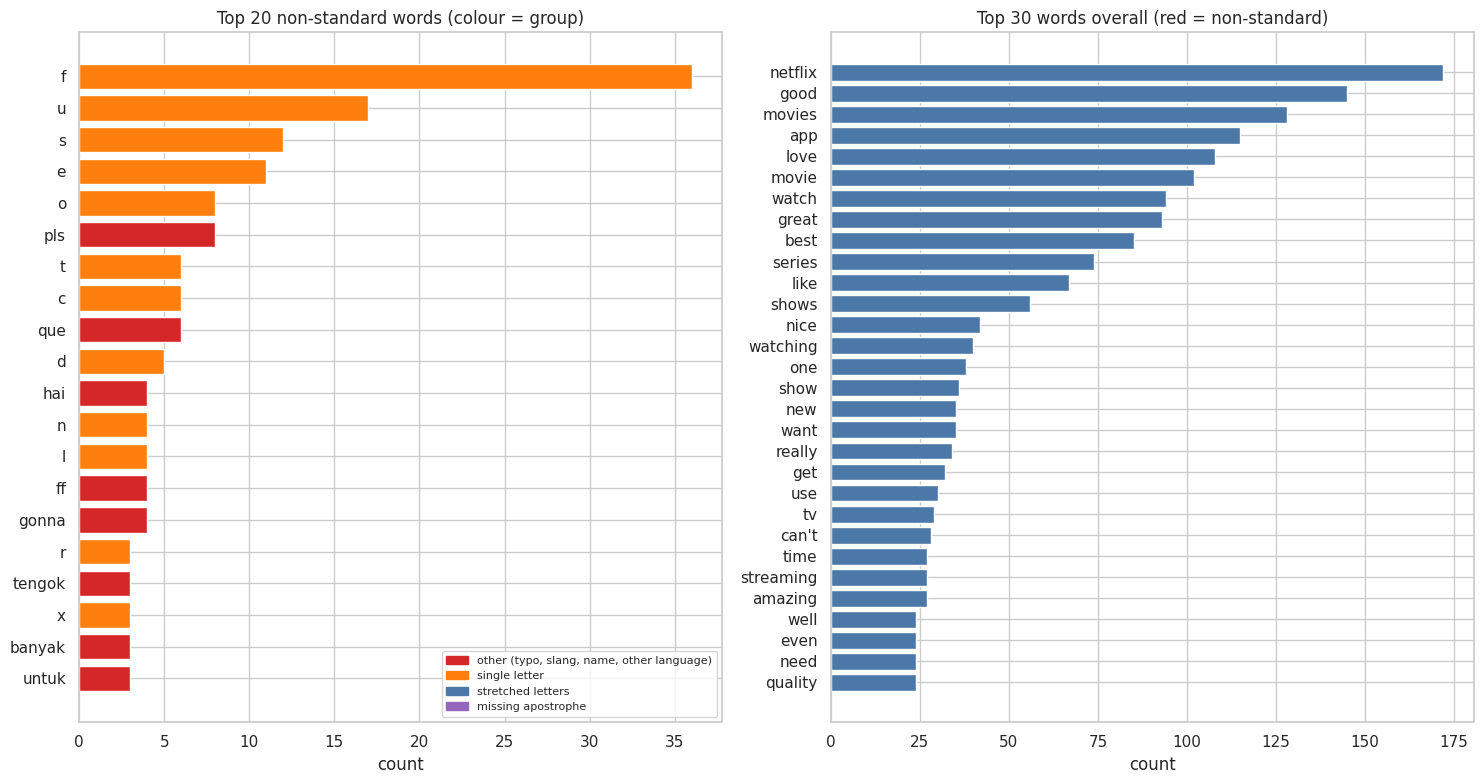

Non-standard words inside the top 50 words: []

Non-standard words as % of all words, per rating:
score
1     5.35
2    12.17
3     4.57
4     6.12
5     3.88
Name: tokens, dtype: float64


In [ ]:
categoryPalette = dict(zip(categorySummary.index, ['#d62728', '#ff7f0e', '#4c78a8', '#9467bd']))

topNonStandard = nonStandardTable.sort_values('count', ascending=False).head(20).iloc[::-1]
top30Overall = Counter(t for tokenList in dfReviews['tokensNoStop'] for t in tokenList).most_common(30)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes[0].barh(topNonStandard['word'], topNonStandard['count'],
             color=[categoryPalette.get(c, '#9e9e9e') for c in topNonStandard['category']])
axes[0].set_title('Top 20 non-standard words (colour = group)')
axes[0].set_xlabel('count')
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in categoryPalette.values()]
axes[0].legend(handles, categoryPalette.keys(), loc='lower right', fontsize=8)

labels = [pair[0] for pair in top30Overall][::-1]
values = [pair[1] for pair in top30Overall][::-1]
axes[1].barh(labels, values, color=['#d62728' if w in nonStandardCounter else '#4c78a8' for w in labels])
axes[1].set_title('Top 30 words overall (red = non-standard)')
axes[1].set_xlabel('count')
plt.tight_layout()
plt.show()

nonStandardInTop50 = [w for w, _ in Counter(t for tl in dfReviews['tokensNoStop'] for t in tl).most_common(50) if w in nonStandardCounter]
print('Non-standard words inside the top 50 words:', nonStandardInTop50)

nonStandardShareByRating = dfReviews.groupby('score')['tokens'].apply(
    lambda s: sum(t in nonStandardCounter for tl in s for t in tl) / max(sum(len(tl) for tl in s), 1) * 100)
print()
print('Non-standard words as % of all words, per rating:')
print(nonStandardShareByRating.round(2))

About 2 in 10 reviews (21.5%) have at least one non-standard word, but these are only about 5% of all words and mostly rare. The biggest group is "other": slang ("pls", "gonna"), other-language words ("que", "hai", "untuk"), and abbreviations ("ff", "bf"). Single letters are second ("u", and spaced letters like "S T E A L I N G"). Missing apostrophes and stretched letters almost never appear. Rating 2 has the highest share (12%), but it has only 38 reviews, so I do not trust it much.

So I do not need a big spelling correction. A small slang list, joining spaced letters, removing single letters, and handling other-language words is enough.

### **Part 11: Main Topics in the Reviews**
I made my own keyword groups which is ads, price, account and login, technical problems, content, video and sound quality, and general praise. A review belongs to a topic if it has one keyword. This is a not an exact measure. The heatmap shows the percentage of reviews in each rating for each topic.

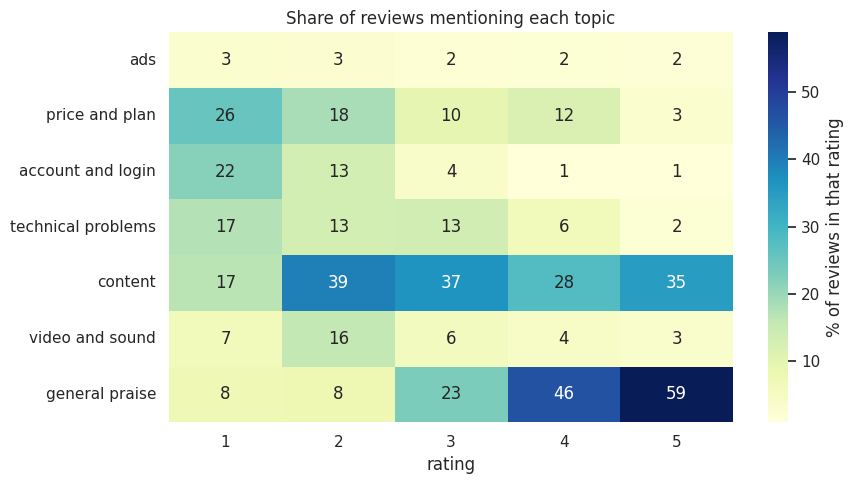

In [ ]:
themeKeywords = {
    'ads': ['ad', 'ads', 'advert', 'adverts', 'advertisement', 'advertisements', 'commercial', 'commercials'],
    'price and plan': ['price', 'prices', 'expensive', 'cost', 'costs', 'pay', 'paying', 'paid', 'subscription',
                       'plan', 'plans', 'money', 'cheap', 'free', 'charge', 'charged', 'fee'],
    'account and login': ['account', 'accounts', 'login', 'log', 'password', 'sign', 'profile', 'profiles',
                          'email', 'verify', 'verification', 'code', 'device', 'devices', 'household'],
    'technical problems': ['bug', 'bugs', 'crash', 'crashes', 'glitch', 'glitches', 'error', 'buffering', 'freeze',
                           'freezes', 'lag', 'laggy', 'loading', 'slow', 'fix', 'update', 'stuck', 'working',
                           'work', 'works', 'issue', 'issues', 'problem', 'problems'],
    'content': ['movie', 'movies', 'show', 'shows', 'series', 'content', 'episode', 'episodes', 'season',
                'seasons', 'library', 'selection', 'film', 'films'],
    'video and sound': ['quality', 'hd', 'resolution', 'audio', 'sound', 'subtitle', 'subtitles', 'captions',
                        'screen', 'picture'],
    'general praise': ['love', 'great', 'good', 'best', 'amazing', 'awesome', 'nice', 'excellent', 'perfect',
                       'wonderful', 'favorite', 'enjoy'],
}

themeFlags = pd.DataFrame({
    theme: dfReviews['tokens'].apply(lambda tokenList, kw=set(keywords): any(t in kw for t in tokenList))
    for theme, keywords in themeKeywords.items()
})

themeByRating = themeFlags.groupby(dfReviews['score']).mean().T * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(themeByRating, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': '% of reviews in that rating'}, ax=ax)
ax.set_xlabel('rating')
ax.set_ylabel('')
ax.set_title('Share of reviews mentioning each topic')
plt.tight_layout()
plt.show()

Problem topics (ads, price, account, technical problems) are stronger in low ratings, and general praise is stronger in high ratings. Content is mentioned in all ratings. So the text carries information about the rating, and a text model should be able to learn something useful.

### **Part 12: Does the Text Match the Rating?**
I use VADER (score from -1 to +1) as a rough check of whether the text agrees with the stars.

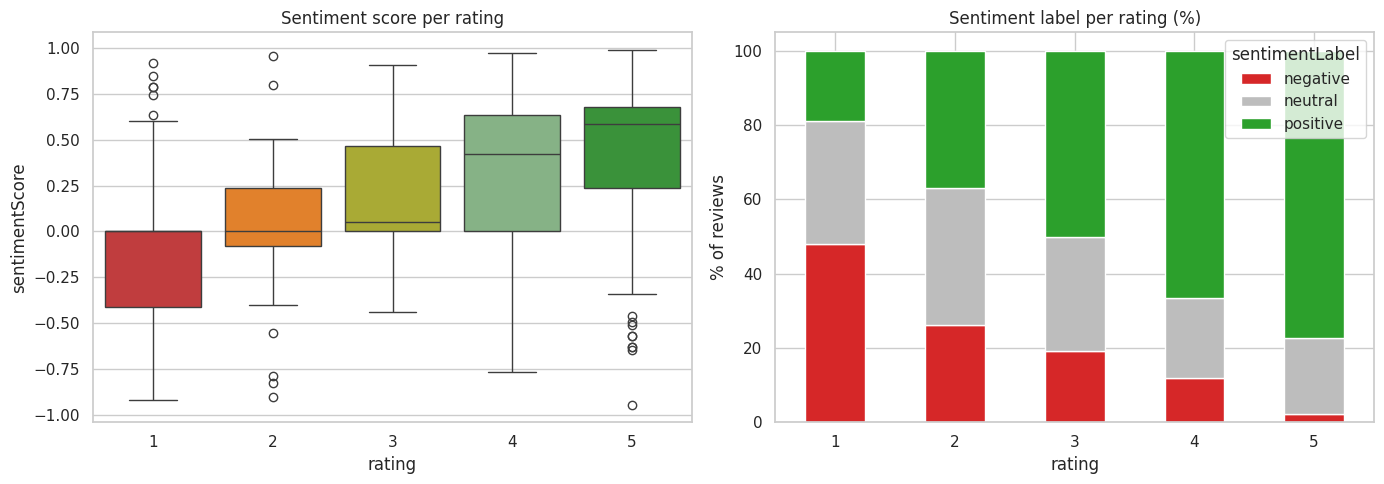

In [ ]:
sentimentAnalyzer = SentimentIntensityAnalyzer()
dfReviews['sentimentScore'] = dfReviews['content'].apply(lambda text: sentimentAnalyzer.polarity_scores(text)['compound'])
dfReviews['sentimentLabel'] = pd.cut(dfReviews['sentimentScore'], bins=[-1.01, -0.05, 0.05, 1.01],
                                     labels=['negative', 'neutral', 'positive'])

crossTab = pd.crosstab(dfReviews['score'], dfReviews['sentimentLabel'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=dfReviews, x='score', y='sentimentScore', hue='score', order=ratingOrder,
            palette=ratingColors, legend=False, ax=axes[0])
axes[0].set_title('Sentiment score per rating')
axes[0].set_xlabel('rating')

crossTab.plot(kind='bar', stacked=True, color=['#d62728', '#bdbdbd', '#2ca02c'], ax=axes[1])
axes[1].set_title('Sentiment label per rating (%)')
axes[1].set_xlabel('rating')
axes[1].set_ylabel('% of reviews')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
lowButPositive = dfReviews[(dfReviews['score'] <= 2) & (dfReviews['sentimentScore'] > 0.5)]
highButNegative = dfReviews[(dfReviews['score'] >= 4) & (dfReviews['sentimentScore'] < -0.5)]

print('Low rating (1-2) but clearly positive text:', len(lowButPositive))
display(lowButPositive[['content', 'score', 'sentimentScore']].head(8))

print('High rating (4-5) but clearly negative text:', len(highButNegative))
display(highButNegative[['content', 'score', 'sentimentScore']].head(8))

Low rating (1-2) but clearly positive text: 12


,content,score,sentimentScore
24,more expensive than it's worth but there's some ok stuff on here. get a different service if you have to pick one th...,2,0.5023
111,thank u for S T E A L I N G money from me!!! so proud of how u S T E A L these days. straight from my wallet gone be...,1,0.9210
129,"Has a couple good original hits, isn't worth the asking price.",1,0.5475
203,this app is so worst that my entire 2 month subscription is gone.... I'm not able to access any series/movies. initi...,1,0.6027
288,"yes they have a ton of content, but at least at this time they have added everything from other services. I would re...",2,0.7994
326,"to bright, takes over phones brightness controls and won't go as low as the phone can go, blinding at night",1,0.7441
348,why can't I just use my phone to adjust the brightness? the built in brightness slider on the app doesn't go dim enough,1,0.6369
673,This app aint worth the gum off my shoe let alone $20 a month for ad free. The beauty of buisness is watching a comp...,1,0.7866


High rating (4-5) but clearly negative text: 10


,content,score,sentimentScore
226,thanks for braving the ways into a Savage new world. if it wasn't for guys like you we wouldn't have America to be l...,5,-0.6460
247,It's my favourite horror film.,5,-0.5719
279,it's peak but sad,5,-0.6310
432,me Gusta pero les hace falta poner una lista de todas las películas que viste sin desaparecerlas,4,-0.5574
501,"This film's story resonates with real life in today's underprivileged societies. Ignorance, neglect of parents and f...",5,-0.9450
510,i lobe it but also hate it bcz i have to pay ro watch,4,-0.7684
642,I can't do the code i hate it,5,-0.5719
664,"Very real. Iron Mike, as I'd never seen before. Great storytelling.",5,-0.5096


On average, higher ratings have more positive text, so text and rating agree in general. But 12 reviews have a low rating with positive text, and 10 have a high rating with negative text. Reading them, I see three reasons:
- sarcasm or mixed reviews ("thank u for S T E A L I N G money")
- negative words that describe the movie, not the app ("peak but sad")
- typos or other languages that VADER cannot read

So the labels are a little noisy, and perfect accuracy is not realistic.

### **Part 13: Special Cases in the Text**
Before preprocessing, I check repeated reviews, reviews that become empty after cleaning, other languages, and the most used emojis.

In [ ]:
print('Most repeated reviews (after cleaning):')
print(dfReviews['cleanText'].value_counts().head(10))
print()

emptyReviews = dfReviews[dfReviews['cleanText'] == '']
print('Reviews that are empty after cleaning:', len(emptyReviews))
print('Per rating:')
print(emptyReviews['score'].value_counts().sort_index())
display(emptyReviews[['content', 'score']].head(5))

Most repeated reviews (after cleaning):
cleanText
                  32
nice               6
i love netflix     5
great              5
i love it          5
good               5
very good          4
best               3
excellent          3
superb             3
Name: count, dtype: int64

Reviews that are empty after cleaning: 32
Per rating:
score
2     1
4     5
5    26
Name: count, dtype: int64


,content,score
9,గోవూడ్,5
21,👌👌💯,5
59,😍,5
63,👍🏼,5
84,💕💕,5


In [ ]:
def getNonAsciiLetterRatio(text):
    letters = [char for char in text if char.isalpha()]
    if not letters:
        return 0.0
    return sum(not char.isascii() for char in letters) / len(letters)

dfReviews['nonAsciiRatio'] = dfReviews['content'].apply(getNonAsciiLetterRatio)
otherLanguage = dfReviews[dfReviews['nonAsciiRatio'] > 0.3]

print('Reviews mostly written in non-latin letters:', len(otherLanguage))
display(otherLanguage[['content', 'score']].head(5))

emojiCounter = Counter(emoji for text in dfReviews['content'] for emoji in emojiPattern.findall(text))
print('Total emojis:', sum(emojiCounter.values()))
print('Most common emojis:', emojiCounter.most_common(10))

Reviews mostly written in non-latin letters: 9


,content,score
9,గోవూడ్,5
29,best सीरीज वर्ल्ड,5
165,बैकसाउंड परफेक्ट,2
189,veri गुड,5
192,गुड,4


Total emojis: 489
Most common emojis: [('👍', 111), ('❤', 34), ('😍', 23), ('👌', 21), ('🥰', 15), ('😊', 14), ('✨', 13), ('😘', 12), ('😃', 11), ('♥', 11)]


Many reviews are the same short phrase ("nice", "great", "good", "i love it"), so there is a lot of generic text.

32 reviews become empty when I keep only letters: 26 are rating 5, 5 are rating 4, and 1 is rating 2. Most contain only emojis like 👍 (the most used, 111 times) or 😍, so I will convert emojis to words to keep this positive signal.

9 reviews are mostly in non-latin letters (Hindi, Telugu), and a few latin-letter reviews are in other languages ("me gusta", "untuk"), which my check cannot find. They are few, so I will not remove them on purpose.

### **Part 14: Summary of the Exploration**
I print the key numbers from the analysis in one place.

In [ ]:
print('DATA')
print(f'  reviews: {len(dfReviews)}')
print(f'  rating 5: {ratingCounts[5] / len(dfReviews):.1%}, rating 1: {ratingCounts[1] / len(dfReviews):.1%}, '
      f'rating 2: {ratingCounts[2] / len(dfReviews):.1%}')
print(f'  biggest class / smallest class: {imbalanceRatio:.1f}x')
print()
print('LENGTH')
print(f'  median words per review: {dfReviews["wordCount"].median():.0f}')
print(f'  reviews with 3 words or fewer: {dfReviews["isShort"].mean():.1%}')
print()
print('TEXT QUALITY')
print(f'  stopwords share of all words: {stopShare:.1%}')
print(f'  non-standard words share of all words: {nonStandardTokens / totalTokens:.1%}')
print(f'  reviews with a non-standard word: {reviewsWithNonStandard:.1%}')
print(f'  reviews empty after cleaning: {len(emptyReviews)}')
print(f'  reviews mostly non-latin: {len(otherLanguage)}')
print()
print('SENTIMENT CHECK')
print(f'  low rating but positive text: {len(lowButPositive)}')
print(f'  high rating but negative text: {len(highButNegative)}')

DATA
  reviews: 1000
  rating 5: 68.4%, rating 1: 13.3%, rating 2: 3.8%
  biggest class / smallest class: 18.0x

LENGTH
  median words per review: 6
  reviews with 3 words or fewer: 31.6%

TEXT QUALITY
  stopwords share of all words: 42.6%
  non-standard words share of all words: 5.0%
  reviews with a non-standard word: 21.5%
  reviews empty after cleaning: 32
  reviews mostly non-latin: 9

SENTIMENT CHECK
  low rating but positive text: 12
  high rating but negative text: 10


### **EDA Insight**

**Data**
- The data is imbalanced: rating 5 is by far the biggest, so I will not rely on accuracy alone.
- Reviews are short and often generic ("good", "nice").
- Rating and text agree in general, but the labels are a little noisy, and some reviews talk about the movies, not the app.

**Words**
- Negations ("not", "no", "don't") are important for meaning.
- "netflix", "app", and "movies" appear in every rating. Problem words (account, price, ads, not working) point to low ratings, and praise words point to high ratings.
- Non-standard words are in about 2 of 10 reviews but only about 5% of all words: mostly slang, other-language words, and single letters.
- Emojis and exclamation marks differ between ratings.

## **3. Text Preprocessing**
The raw text has capitals, links, emojis, short forms ("u", "pls"), stretched words ("sooo"), and many words with no meaning. The task also wants tokens that follow grammar, keep the meaning, and keep the word class.

So I use lemmatization with POS tags, not stemming. Stemming cuts words with fixed rules and can make non-words ("movies" becomes "movi"). Lemmatization gives the dictionary form ("movies" becomes "movie"), and the POS tag helps it choose the right form for nouns, verbs, and adjectives.

In [ ]:
!pip install emoji

In [ ]:
import emoji
import unicodedata
from itertools import groupby, product
from nltk import pos_tag
from nltk.stem import PorterStemmer, WordNetLemmatizer

for resourceName in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'wordnet', 'omw-1.4']:
    nltk.download(resourceName, quiet=True)

dfPrep = dfReviews[['content', 'score']].copy()

### **Step 1: Basic Cleaning**
I lowercase the text, remove links and HTML tags, change the curly apostrophe to a normal one, and remove invisible emoji modifier characters (skin tones, variation marks) so they do not create noise in the next step.

In [ ]:
def joinSpacedLetters(text):
    return re.sub(r'\b[a-z](?:[\s.]+[a-z]){2,}\b', lambda match: re.sub(r'[\s.]+', '', match.group(0)), text)

def basicClean(text):
    text = unicodedata.normalize('NFKC', text).lower()
    text = text.replace('\u2019', "'").replace('\u2018', "'").replace('\ufe0f', '')
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub('[\U0001F3FB-\U0001F3FF]', '', text)
    return joinSpacedLetters(text)

### **Step 2: Convert Emojis to Words**
In the EDA, 32 reviews became empty because they had only emojis, and they are almost all positive. So I convert emojis to words. For common emojis I choose a simple feeling word myself (👍 becomes "good", 😍 becomes "love"), which is cleaner than long official names like "smiling face with heart-eyes". For other emojis I use the name from the `emoji` library.

In [ ]:
emojiGroups = {
    'good': '👍👌👏🙌💯🔥',
    'love': '❤♥😍🥰😘💕💖💗💙💜💛💚😻',
    'happy': '😊😃😄😁😀🙂☺',
    'funny': '😂🤣😆',
    'sad': '😭😢😞😔☹🙁',
    'angry': '😡😠🤬😤',
    'bad': '👎🤮💩',
    'thanks': '🙏',
}
emojiMeaning = {char: meaning for meaning, chars in emojiGroups.items() for char in chars}

def convertEmoji(text):
    result = []
    for char in text:
        if char in emojiMeaning:
            result.append(f' {emojiMeaning[char]} ')
        elif char in emoji.EMOJI_DATA:
            name = emoji.demojize(char, delimiters=(' ', ' ')).replace('_', ' ')
            result.append(' ' + re.sub(r'\b(face|with|of)\b', ' ', name) + ' ')
        else:
            result.append(char)
    return ''.join(result)

### **Step 3: Expand Contractions and Fix Slang**
I change short forms to full forms ("can't" to "cannot", "I'm" to "i am"), so the text follows normal grammar and "not" becomes a separate word that I can keep. I also fix a small list of clear slang from the EDA ("u", "pls", "gonna"), so I do not change a meaning by mistake.

In [ ]:
contractionMap = {
    "can't": 'cannot', "won't": 'will not', "shan't": 'shall not', "ain't": 'is not', "let's": 'let us',
    "i'm": 'i am', "it's": 'it is', "that's": 'that is', "what's": 'what is', "there's": 'there is',
    "here's": 'here is', "he's": 'he is', "she's": 'she is', "who's": 'who is',
}
suffixRules = [("n't", ' not'), ("'re", ' are'), ("'ve", ' have'), ("'ll", ' will'), ("'d", ' would'), ("'m", ' am')]
slangMap = {
    'u': 'you', 'ur': 'your', 'r': 'are', 'pls': 'please', 'plz': 'please', 'thx': 'thanks', 'thanx': 'thanks',
    'gonna': 'going to', 'wanna': 'want to', 'gotta': 'got to', 'gud': 'good', 'bcz': 'because', 'coz': 'because',
    'cuz': 'because', 'bcoz': 'because', 'ok': 'okay', 'tbh': 'to be honest', 'omg': 'oh my god', 'lol': 'funny',
    'luv': 'love', 'awsome': 'awesome', 'dont': 'do not', 'cant': 'cannot', 'wont': 'will not', 'im': 'i am',
    'ive': 'i have', 'didnt': 'did not', 'doesnt': 'does not', 'isnt': 'is not', 'wasnt': 'was not',
    'couldnt': 'could not', 'youre': 'you are', 'thats': 'that is',
}
slangMap.update({'idk': 'i do not know', 'vry': 'very', 'veri': 'very', 'usefull': 'useful', 'thru': 'through'})

def normalizeWord(match):
    word = match.group(0).strip("'")
    if word in contractionMap:
        return contractionMap[word]
    if word in slangMap:
        return slangMap[word]
    for suffix, replacement in suffixRules:
        if word.endswith(suffix) and len(word) > len(suffix):
            return word[:-len(suffix)] + replacement
    if word.endswith("'s"):
        return word[:-2]
    return word

### **Step 4: Keep Only Letters and Shorten Stretched Letters**
I remove digits, punctuation, symbols, and non-latin scripts (an English model cannot use them). For stretched words like "goooood", I try keeping one or two letters of each stretched part and use the first option that is a real English word, because "good" has two o's on purpose. If none works, I use the two-letter version.

In [ ]:
def removeNonLetters(text):
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def fixStretched(word):
    groups = [(char, len(list(items))) for char, items in groupby(word)]
    options = [[2, 1] if count >= 3 else [count] for _, count in groups]
    candidates = [''.join(char * size for (char, _), size in zip(groups, sizes)) for sizes in product(*options)]
    for candidate in candidates:
        if isStandardWord(candidate):
            return candidate
    return candidates[0]

def fixAllStretched(text):
    return ' '.join(fixStretched(word) if re.search(r'(.)\1{2,}', word) else word for word in text.split())

### **Step 5: Stemming vs Lemmatization**
I run both on the same sentence. The stemmer cuts words with simple rules. The lemmatizer uses the POS tag of each word to find the dictionary form.

In [ ]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def getWordnetPos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    if tag.startswith('V'):
        return wordnet.VERB
    if tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

demoSentence = 'the amazing movies were better and i loved watching the episodes happily'
demoTagged = pos_tag(demoSentence.split())

pd.DataFrame({
    'Word': [word for word, _ in demoTagged],
    'POS tag': [tag for _, tag in demoTagged],
    'Stemming': [stemmer.stem(word) for word, _ in demoTagged],
    'Lemmatization': [lemmatizer.lemmatize(word, getWordnetPos(tag)) for word, tag in demoTagged],
})

,Word,POS tag,Stemming,Lemmatization
0,the,DT,the,the
1,amazing,JJ,amaz,amazing
2,movies,NNS,movi,movie
3,were,VBD,were,be
4,better,JJR,better,good
5,and,CC,and,and
6,i,JJ,i,i
7,loved,VBD,love,love
8,watching,VBG,watch,watch
9,the,DT,the,the


The stemmer gives non-words ("movi", "episod", "happili"). The lemmatizer always gives real words and uses the POS tag to choose the form ("loved" becomes "love" as a verb, "movies" becomes "movie" as a noun). The task wants grammar, meaning, and word class to be kept, so I use lemmatization.

### **Step 6: Lemmatization and Stopword Removal**
I do POS tagging before removing stopwords, because the tag depends on the words around it. Then I remove stopwords and one-letter words, but I keep "no", "not", "nor", and "cannot", because they flip the meaning ("not good" is the opposite of "good").

In [ ]:
keepWords = negationWords | {'cannot'}

def lemmatizeText(text):
    tokens = text.split()
    return [(token, lemmatizer.lemmatize(token, getWordnetPos(tag))) for token, tag in pos_tag(tokens)]

def preprocessReview(text):
    text = basicClean(text)
    text = convertEmoji(text)
    text = re.sub(r"[a-z']+", normalizeWord, text)
    text = removeNonLetters(text)
    text = fixAllStretched(text)
    return [lemma for token, lemma in lemmatizeText(text)
            if len(lemma) > 1 and (token in keepWords or (token not in stopWords and lemma not in stopWords))]

### **Step-by-Step Example**
I follow four reviews (with emojis, slang, and contractions) through the steps to check each step.

In [ ]:
def showSteps(text):
    afterBasic = basicClean(text)
    afterEmoji = convertEmoji(afterBasic)
    afterNormalize = re.sub(r"[a-z']+", normalizeWord, afterEmoji)
    afterLetters = fixAllStretched(removeNonLetters(afterNormalize))
    print('Original               :', text)
    print('After basic cleaning   :', afterBasic)
    print('After emoji conversion :', re.sub(r'\s+', ' ', afterEmoji).strip())
    print('After slang fix        :', re.sub(r'\s+', ' ', afterNormalize).strip())
    print('After letters only     :', afterLetters)
    print('Final tokens           :', preprocessReview(text))
    print('-' * 100)

exampleTexts = [
    'I am so addicted to this 😫 😩',
    'Wonderful!!!! Well written. Acting is excellent! I cried on all episodes!',
    'hey please dont remove this lively movie called letter to Juliet from netflix',
    'love your movies, u keep up with "new ones!"',
]
for exampleText in exampleTexts:
    showSteps(exampleText)

Original               : I am so addicted to this 😫 😩
After basic cleaning   : i am so addicted to this 😫 😩
After emoji conversion : i am so addicted to this tired weary
After slang fix        : i am so addicted to this tired weary
After letters only     : i am so addicted to this tired weary
Final tokens           : ['addicted', 'tire', 'weary']
----------------------------------------------------------------------------------------------------
Original               : Wonderful!!!! Well written. Acting is excellent! I cried on all episodes!
After basic cleaning   : wonderful!!!! well written. acting is excellent! i cried on all episodes!
After emoji conversion : wonderful!!!! well written. acting is excellent! i cried on all episodes!
After slang fix        : wonderful!!!! well written. acting is excellent! i cried on all episodes!
After letters only     : wonderful well written acting is excellent i cried on all episodes
Final tokens           : ['wonderful', 'well', 'write', 'actin

### **Run the Preprocessing on All Reviews**

I apply all steps to the 1,000 reviews and save tokens (a list of words, for Word2Vec) and cleanText (the words joined into one string, for TF-IDF).

In [ ]:
dfPrep['tokens'] = dfPrep['content'].apply(preprocessReview)
dfPrep['cleanText'] = dfPrep['tokens'].apply(' '.join)

display(dfPrep[['content', 'cleanText', 'score']].sample(8, random_state=3))

,content,cleanText,score
642,I can't do the code i hate it,cannot code hate,5
762,Absolutely the best! Fast and lightweight = runs well on slower devices. Can truly work completely offline when trav...,absolutely best fast lightweight run well slow device truly work completely offline travel not constantly annoy expi...,5
909,Anime,anime,5
199,my love is good,love good,5
586,fix your app. What's the point of buying netflix if the app doesn't work properly. The player keeps buffering. and I...,fix app point buy netflix app not work properly player keep buffer cannot watch anything even download downloaded vi...,1
797,waste of Time and it's Cool,waste time cool,5
652,easy to use,easy use,4
755,Is good platform for us to watch any kind of movies...,good platform watch kind movie,5


### **Step 7: Handle Empty Reviews**

 Model cannot learn from empty text, so I check the reviews with no token left and remove them. I also check their ratings, so I do not lose a whole class.

In [ ]:
emptyMask = dfPrep['tokens'].str.len() == 0
print('Reviews with no token left:', emptyMask.sum())
print()
print('Their ratings:')
print(dfPrep.loc[emptyMask, 'score'].value_counts().sort_index())
display(dfPrep.loc[emptyMask, ['content', 'score']].head(8))

dfClean = dfPrep.loc[~emptyMask].reset_index(drop=True)
print()
print('Reviews after removing empty ones:', len(dfClean))
print(dfClean['score'].value_counts().sort_index())

Reviews with no token left: 10

Their ratings:
score
2    1
4    2
5    7
Name: count, dtype: int64


,content,score
9,గోవూడ్,5
165,बैकसाउंड परफेक्ट,2
189,veri गुड,5
192,गुड,4
304,أفضل تطبيق بالعالم,5
375,☆☆☆☆☆,5
470,我想看的戏大部分都在这里 方便 好看,4
480,मूवीज बहुत ही अच्छी रहती हैं प्लीज एक रिक्वेस्ट है के वीडियो की क्वालिटी अच्छा करने का सो गया एचडी में या फुल एचडी में,5



Reviews after removing empty ones: 990
score
1    133
2     37
3     52
4     91
5    677
Name: count, dtype: int64


Only 10 reviews are empty now, compared with 32 in the EDA, because emojis became words. The remaining ones are only non-latin letters (Telugu, Hindi, Arabic, Chinese), only symbols ("☆☆☆☆☆"), or spaced letters ("G. O. A. T"). I remove them. Every rating is still present (rating 5 loses 7 reviews, rating 4 loses 2, and rating 2 loses 1).

### **Result: Before and After Preprocessing**

I compare the vocabulary size, the average review length, and the share of non-standard words with the EDA numbers. Good preprocessing should make the vocabulary smaller and remove most non-standard words, without emptying the reviews.

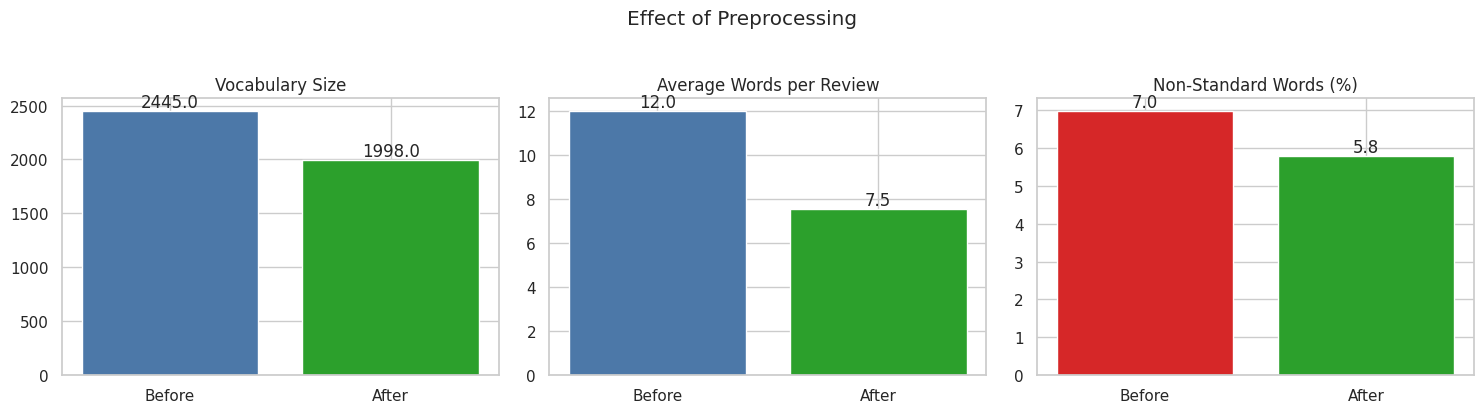

Most common non-standard words that are still left:
[('que', 6), ('hai', 4), ('ff', 4), ('tengok', 3), ('banyak', 3), ('untuk', 3), ('bf', 3), ('achcha', 2), ('aur', 2), ('dekhne', 2), ('ke', 2), ('tak', 2), ('lagi', 2), ('osm', 2), ('filem', 2)]


In [ ]:
vocabBefore = len(set(allTokens))
vocabAfter = len({token for tokenList in dfClean['tokens'] for token in tokenList})
lengthBefore = dfReviews['tokens'].str.len().mean()
lengthAfter = dfClean['tokens'].str.len().mean()

tokensAfter = [token for tokenList in dfClean['tokens'] for token in tokenList]
nonStandardAfter = Counter(token for token in tokensAfter if not isStandardWord(token))
tokensBeforeNoStop = [token for tokenList in dfReviews['tokensNoStop'] for token in tokenList]
shareBefore = sum(not isStandardWord(token) for token in tokensBeforeNoStop) / len(tokensBeforeNoStop) * 100
shareAfter = sum(nonStandardAfter.values()) / len(tokensAfter) * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, title, values, color in zip(
        axes,
        ['Vocabulary Size', 'Average Words per Review', 'Non-Standard Words (%)'],
        [(vocabBefore, vocabAfter), (lengthBefore, lengthAfter), (shareBefore, shareAfter)],
        ['#4c78a8', '#4c78a8', '#d62728']):
    bars = ax.bar(['Before', 'After'], values, color=[color, '#2ca02c'])
    ax.bar_label(bars, fmt='%.1f')
    ax.set_title(title)
plt.suptitle('Effect of Preprocessing', y=1.03)
plt.tight_layout()
plt.show()

print('Most common non-standard words that are still left:')
print(nonStandardAfter.most_common(15))

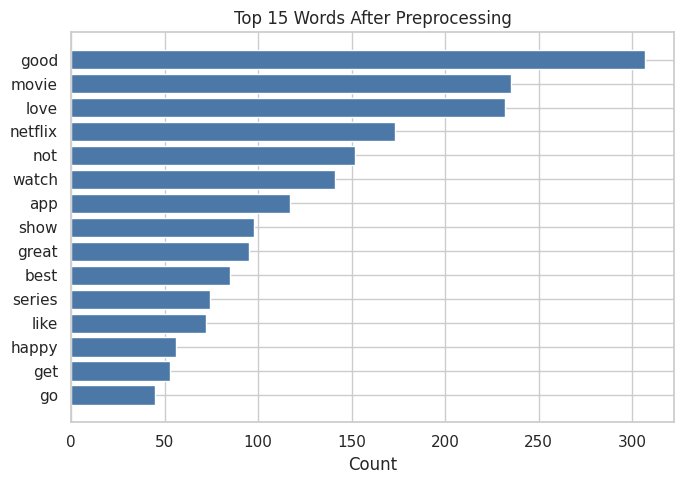

,Rating 1,Rating 2,Rating 3,Rating 4,Rating 5
1,not (32%),movie (30%),not (37%),good (23%),good (23%)
2,netflix (24%),not (30%),movie (21%),movie (20%),movie (22%)
3,app (20%),get (19%),watch (17%),like (12%),love (20%)
4,cannot (12%),watch (14%),app (15%),app (11%),netflix (16%)
5,use (12%),app (14%),good (15%),not (11%),great (12%)
6,watch (12%),netflix (14%),get (12%),best (11%),watch (11%)
7,get (11%),time (11%),series (12%),love (10%),best (10%)
8,go (10%),good (11%),even (10%),watch (10%),show (9%)
9,work (9%),series (11%),like (10%),nice (9%),app (8%)
10,no (9%),want (11%),show (10%),show (8%),series (8%)


In [ ]:
topWordsAfter = Counter(tokensAfter).most_common(15)

fig, ax = plt.subplots(figsize=(7, 5))
drawBar(ax, topWordsAfter, 'Top 15 Words After Preprocessing', '#4c78a8')
ax.set_xlabel('Count')
plt.tight_layout()
plt.show()

topWordsAfterByRating = {
    rating: topDocFreq(dfClean.loc[dfClean['score'] == rating, 'tokens'].tolist(), 10)
    for rating in ratingOrder
}
topWordsAfterTable = pd.DataFrame({
    f'Rating {rating}': [f'{word} ({share:.0%})' for word, share in topWordsAfterByRating[rating]]
    for rating in ratingOrder
})
topWordsAfterTable.index = range(1, 11)
topWordsAfterTable

The vocabulary is smaller, because word forms ("movies", "movie") become one token and stopwords are removed. The remaining tokens are real words with their meaning and word class. The words that are still non-standard are mostly other-language words ("que", "hai", "untuk", "tengok") and a few short forms ("ff", "bf", "osm").

Keeping negations was a good choice, "not" is the top word in ratings 1 and 3 (32% and 37% of reviews), second in rating 2 (30%), but only 11% in rating 4 and not in the top 10 of rating 5. "cannot" and "no" are also common in rating 1. Emoji-only reviews are mostly saved (22 of the 32), because emojis became words like "good" and "love".

The result is saved in dfClean (cleanText and tokens) and is the input for Question 4.

## **4. Text Representation**

A model needs numbers, so I turn each review into a vector with two methods:
1. **TF-IDF**: each number says how important a word is in a review.
2. **Word2Vec**: each word gets a vector learned from its surrounding words with a small neural network, and a review is the average of its word vectors.

I split the data first into train (80%) and test (20%), because both methods learn from the text. If they also learned from the test reviews, the test score would look better than it really is (data leakage). The split is stratified, so each rating keeps the same share in both sets, which matters because rating 2 is very small.

In [ ]:
from sklearn.model_selection import train_test_split

dfTrain, dfTest = train_test_split(dfClean, test_size=0.2, random_state=42, stratify=dfClean['score'])
dfTrain = dfTrain.reset_index(drop=True)
dfTest = dfTest.reset_index(drop=True)

yTrain = dfTrain['score'].values
yTest = dfTest['score'].values

splitSummary = pd.DataFrame({
    'Train': dfTrain['score'].value_counts().sort_index(),
    'Test': dfTest['score'].value_counts().sort_index(),
})
splitSummary['Train (%)'] = (splitSummary['Train'] / splitSummary['Train'].sum() * 100).round(1)
splitSummary['Test (%)'] = (splitSummary['Test'] / splitSummary['Test'].sum() * 100).round(1)
print('Train size:', len(dfTrain), '| Test size:', len(dfTest))
splitSummary

Train size: 792 | Test size: 198


,Train,Test,Train (%),Test (%)
score,,,,
1,106,27,13.4,13.6
2,29,8,3.7,4.0
3,42,10,5.3,5.1
4,73,18,9.2,9.1
5,542,135,68.4,68.2


### **Method 1: TF-IDF**

The score of a word in a review is TF x IDF. TF is how often the word appears in the review. IDF is how rare the word is across all reviews (common words like "netflix" get a low value). So a word scores high when it is frequent in this review but rare in the others, which is "how important a word is in a sample".

- ngram_range=(1, 2): single words and two-word phrases, to see things like "not good"
- min_df=2: ignore words and phrases that appear in only one review
- sublinear_tf=True: a word repeated ten times is not ten times more important

The vectorizer is fitted on the train set only.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidfVectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
xTrainTfidf = tfidfVectorizer.fit_transform(dfTrain['cleanText'])
xTestTfidf = tfidfVectorizer.transform(dfTest['cleanText'])

tfidfTerms = tfidfVectorizer.get_feature_names_out()
tfidfSparsity = 1 - xTrainTfidf.nnz / (xTrainTfidf.shape[0] * xTrainTfidf.shape[1])

print('Train matrix shape:', xTrainTfidf.shape)
print('Test matrix shape:', xTestTfidf.shape)
print(f'Share of zero values in the train matrix: {tfidfSparsity:.1%}')

idfTable = pd.Series(tfidfVectorizer.idf_, index=tfidfTerms).sort_values()
print()
print('Terms with the lowest IDF (appear in many reviews, so they get low weight):')
print(idfTable.head(10).round(2))
print()
print('Terms with the highest IDF (appear in few reviews, so they get high weight):')
print(idfTable.tail(5).round(2))

Train matrix shape: (792, 907)
Test matrix shape: (198, 907)
Share of zero values in the train matrix: 99.3%

Terms with the lowest IDF (appear in many reviews, so they get low weight):
movie      2.60
good       2.65
love       2.88
netflix    2.92
not        3.03
watch      3.16
app        3.27
great      3.33
show       3.47
series     3.58
dtype: float64

Terms with the highest IDF (appear in few reviews, so they get high weight):
horror              6.58
however             6.58
would definitely    6.58
absolute            6.58
worthy              6.58
dtype: float64


The train set has 792 reviews and the test set has 198. Each rating has almost the same share in both (for example, rating 5 is 68.4% in train and 68.2% in test), so the split is fair. Rating 2 has only 8 test reviews, so its result will be unstable.

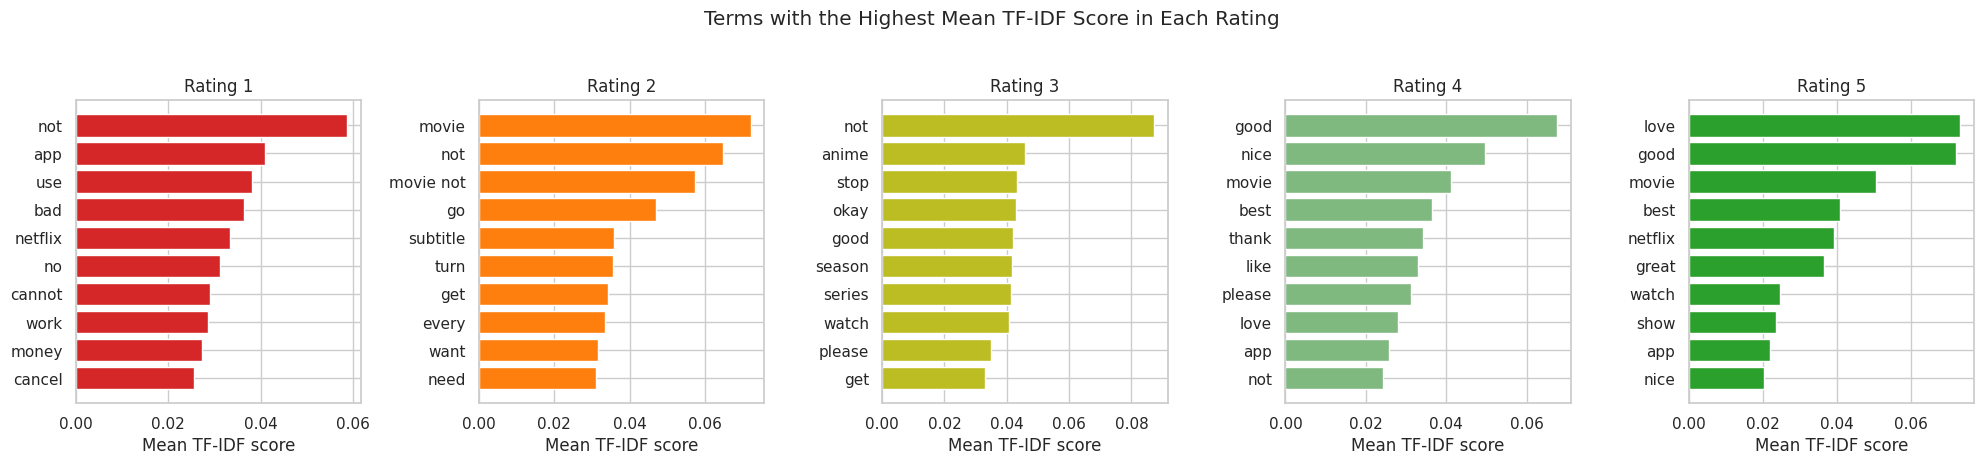

Review: 10/10 All in a movie....!
Clean text: movie
Top terms: [('movie', np.float64(1.0))]

Review: great movie experience
Clean text: great movie experience
Top terms: [('movie experience', np.float64(0.623)), ('great movie', np.float64(0.492)), ('experience', np.float64(0.459)), ('great', np.float64(0.316)), ('movie', np.float64(0.246))]

Review: I love netflicks but not since the adverts have started to come on
Clean text: love netflicks not since advert start come
Top terms: [('since', np.float64(0.558)), ('come', np.float64(0.518)), ('start', np.float64(0.496)), ('not', np.float64(0.302)), ('love', np.float64(0.287))]



In [ ]:
def getTopTfidfTerms(rating, topN=10):
    meanScores = np.asarray(xTrainTfidf[yTrain == rating].mean(axis=0)).ravel()
    order = meanScores.argsort()[::-1][:topN]
    return [(tfidfTerms[i], meanScores[i]) for i in order]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, rating in zip(axes, ratingOrder):
    drawBar(ax, getTopTfidfTerms(rating), f'Rating {rating}', ratingColors[rating])
    ax.set_xlabel('Mean TF-IDF score')
plt.suptitle('Terms with the Highest Mean TF-IDF Score in Each Rating', y=1.03)
plt.tight_layout()
plt.show()

for index in [0, 1, 2]:
    row = xTrainTfidf[index].toarray().ravel()
    topIndex = [i for i in row.argsort()[::-1][:5] if row[i] > 0]
    print('Review:', dfTrain.loc[index, 'content'][:150])
    print('Clean text:', dfTrain.loc[index, 'cleanText'])
    print('Top terms:', [(tfidfTerms[i], round(row[i], 3)) for i in topIndex])
    print()

The TF-IDF matrix has 907 columns, and 99.3% of the values are zero, because each review uses only a few words.

Ratings 1 and 3 are led by "not", and rating 1 also has "bad", "no", "cannot", "money", and "cancel" (problem words). Ratings 4 and 5 are led by "good", "nice", "love", and "best". Rating 2 has no clear pattern.

TF-IDF measures how rare a word is, not how positive or negative it is. In "love netflicks not since advert start come", the top scores go to "since", "come", and "start", while "not" and "love" score lower.

### **Method 2: Word2Vec**

Word2Vec uses a small neural network. In skip-gram, the input is one word and the target is the words around it (inside a window). After training, the hidden-layer weights are the word vectors. Words used in similar situations get similar vectors (for example "good" and "great"), which TF-IDF cannot do. A review vector is the average of its word vectors (all zeros if no word is known).

- vector_size=100: 100 numbers per word
- window=5: 5 words before and after
- min_count=2: ignore words seen only once
- sg=1: skip-gram, which is better for small data
- epochs=100: small data needs more rounds
- seed=42 and workers=1: the same result every time

I train it on the train set only. About 800 short reviews is very small for Word2Vec, so I read the results with care.

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 71.4 MB/s  0:00:00


In [ ]:
from gensim.models import Word2Vec

w2vModel = Word2Vec(sentences=dfTrain['tokens'].tolist(), vector_size=100, window=5, min_count=2,
                    sg=1, epochs=100, seed=42, workers=1)

print('Vocabulary size:', len(w2vModel.wv))
print()
for probeWord in ['good', 'bad', 'not', 'movie', 'pay', 'love']:
    if probeWord in w2vModel.wv.key_to_index:
        similarWords = w2vModel.wv.most_similar(probeWord, topn=5)
        print(f'{probeWord}:', ', '.join(f'{word} ({score:.2f})' for word, score in similarWords))
    else:
        print(f'{probeWord}: not in the vocabulary')

Vocabulary size: 637

good: popcorn (0.59), osm (0.58), collection (0.56), camera (0.56), soo (0.55)
bad: limited (0.61), high (0.60), sonic (0.60), interrupt (0.58), steal (0.57)
not: another (0.46), anymore (0.45), vpn (0.44), interrupt (0.44), fan (0.44)
movie: affordable (0.58), popcorn (0.56), camera (0.54), series (0.53), bunch (0.53)
pay: monthly (0.65), amount (0.64), either (0.63), extra (0.62), boring (0.61)
love: melt (0.77), struck (0.76), strike (0.73), happy (0.71), gorgeous (0.70)


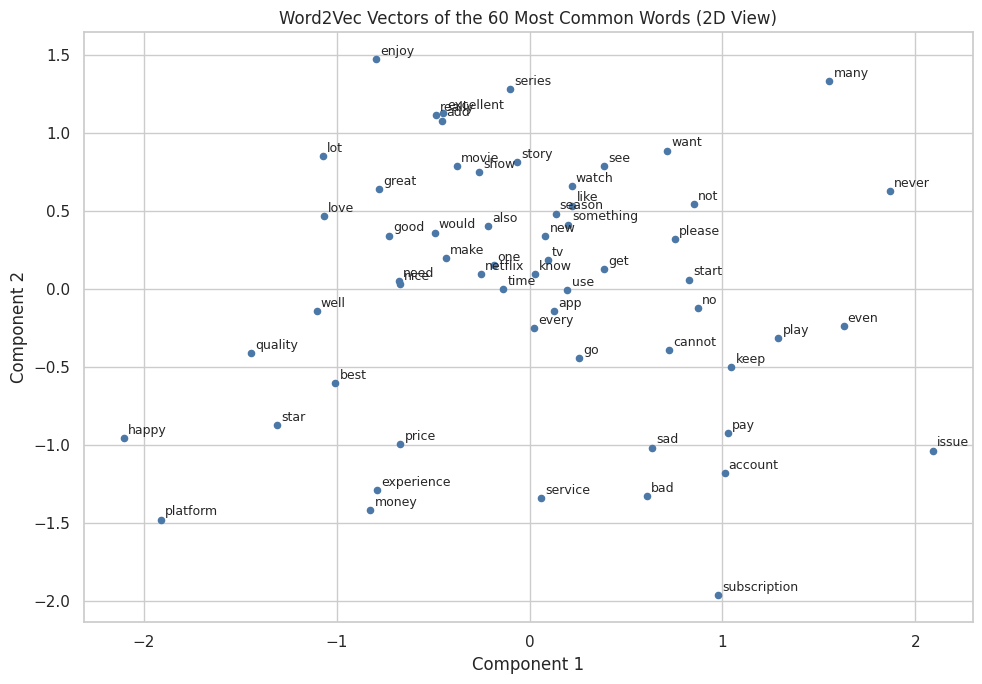

In [ ]:
from sklearn.decomposition import PCA, TruncatedSVD

topWordList = w2vModel.wv.index_to_key[:60]
wordPoints = PCA(n_components=2, random_state=42).fit_transform(w2vModel.wv[topWordList])

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(wordPoints[:, 0], wordPoints[:, 1], color='#4c78a8', s=20)
for word, (xValue, yValue) in zip(topWordList, wordPoints):
    ax.annotate(word, (xValue, yValue), fontsize=9, xytext=(3, 3), textcoords='offset points')
ax.set_title('Word2Vec Vectors of the 60 Most Common Words (2D View)')
ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
plt.tight_layout()
plt.show()

In [ ]:
def getAverageVector(tokenList):
    vectors = [w2vModel.wv[token] for token in tokenList if token in w2vModel.wv.key_to_index]
    if not vectors:
        return np.zeros(w2vModel.vector_size)
    return np.mean(vectors, axis=0)

xTrainW2v = np.array([getAverageVector(tokenList) for tokenList in dfTrain['tokens']])
xTestW2v = np.array([getAverageVector(tokenList) for tokenList in dfTest['tokens']])

def getCoverage(tokenLists):
    total = sum(len(tokenList) for tokenList in tokenLists)
    known = sum(token in w2vModel.wv.key_to_index for tokenList in tokenLists for token in tokenList)
    return known / total * 100

print('Train matrix shape:', xTrainW2v.shape)
print('Test matrix shape:', xTestW2v.shape)
print(f'Words known by the model, train: {getCoverage(dfTrain["tokens"]):.1f}%')
print(f'Words known by the model, test: {getCoverage(dfTest["tokens"]):.1f}%')
print('Reviews with a zero vector, train:', int((np.abs(xTrainW2v).sum(axis=1) == 0).sum()))
print('Reviews with a zero vector, test:', int((np.abs(xTestW2v).sum(axis=1) == 0).sum()))

Train matrix shape: (792, 100)
Test matrix shape: (198, 100)
Words known by the model, train: 82.0%
Words known by the model, test: 72.7%
Reviews with a zero vector, train: 36
Reviews with a zero vector, test: 13


The vocabulary has 637 words. Some neighbours make sense ("pay" is near "monthly" and "extra", "love" is near "happy" and "gorgeous"), but many do not ("good" is near "popcorn" and "camera"), which is expected with about 800 short reviews. In the 2D picture, praise words are mostly on the left and problem words ("issue", "subscription", "pay", "bad", "no", "not") on the right, so the model still learned some positive vs negative difference.

The model knows 82.0% of the train words but only 72.7% of the test words. 36 train reviews (4.5%) and 13 test reviews (6.6%) have a zero vector.

### **Comparing the Two Representations**

I compare the shape and type of the data, then plot each review in 2D (TF-IDF with TruncatedSVD, Word2Vec with PCA), coloured by rating. This is only a rough picture, but mixed colours mean the ratings are not easy to separate.

,Method,Numbers per review,Type,Zero values (%),Meaning of the numbers
0,TF-IDF,907,Sparse,99.3,How important a word is in the review
1,Word2Vec (average),100,Dense,4.5,Place of the review in a meaning space


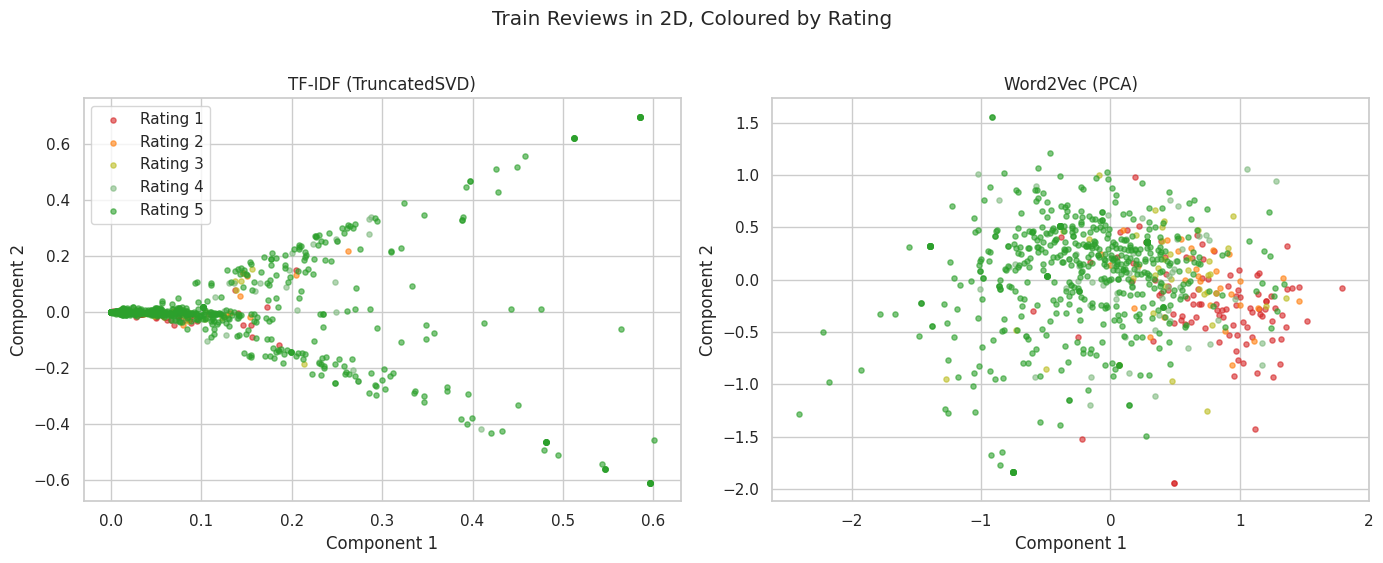

In [ ]:
representationSummary = pd.DataFrame({
    'Method': ['TF-IDF', 'Word2Vec (average)'],
    'Numbers per review': [xTrainTfidf.shape[1], w2vModel.vector_size],
    'Type': ['Sparse', 'Dense'],
    'Zero values (%)': [round(tfidfSparsity * 100, 1), round((xTrainW2v == 0).mean() * 100, 1)],
    'Meaning of the numbers': ['How important a word is in the review', 'Place of the review in a meaning space'],
})
display(representationSummary)

tfidfPoints = TruncatedSVD(n_components=2, random_state=42).fit_transform(xTrainTfidf)
w2vPoints = PCA(n_components=2, random_state=42).fit_transform(xTrainW2v)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, points, title in zip(axes, [tfidfPoints, w2vPoints], ['TF-IDF (TruncatedSVD)', 'Word2Vec (PCA)']):
    for rating in ratingOrder:
        mask = yTrain == rating
        ax.scatter(points[mask, 0], points[mask, 1], s=14, alpha=0.6, color=ratingColors[rating], label=f'Rating {rating}')
    ax.set_title(title)
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
axes[0].legend()
plt.suptitle('Train Reviews in 2D, Coloured by Rating', y=1.02)
plt.tight_layout()
plt.show()

TF-IDF has 907 numbers per review (99.3% zeros). Word2Vec has 100 numbers per review, and zeros appear only in the 4.5% of reviews with no known word.

Neither method separates the ratings fully, but Word2Vec is clearer. Rating 1 is mostly on the right, and rating 5 is more to the left and centre. The TF-IDF picture is hard to read, because most reviews are short and sit near zero, and rating 5 is drawn last and covers the others. A 2D view cannot tell which method predicts better.

Next I use xTrainTfidf, xTestTfidf, xTrainW2v, xTestW2v, yTrain, and yTest.

## **5. Machine Learning Modelling**

I train two algorithms on both representations (4 combinations).
- **SVM**: finds the best boundary between the ratings. It works well on text with many features and few reviews.
- **Random Forest**: many trees vote for a rating.

I do not use Naive Bayes, because the standard version cannot use negative numbers, and Word2Vec vectors have them.

| Algorithm | Hyperparameter | What it does | Values |
|---|---|---|---|
| SVM | C | How strongly a wrong prediction is punished (small = simpler model) | 0.1, 1, 10, 100, 1000 |
| SVM | kernel | Shape of the boundary: linear (straight) or rbf (curved) | linear, rbf |
| Random Forest | n_estimators | Number of trees | 100, 300 |
| Random Forest | max_depth | How deep a tree can grow (deep trees can memorize) | None, 10, 20 |
| Random Forest | min_samples_leaf | Smallest number of reviews in a leaf (bigger = simpler) | 1, 2, 4 |

**Tuning:** GridSearchCV with 5-fold stratified cross-validation on the train set only. I choose by **macro F1**, because accuracy is misleading (always predicting 5 gives about 68%). I also calculate a baseline (always predict rating 5) that a real model must beat.

In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

crossValidation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

representations = {'TF-IDF': xTrainTfidf, 'Word2Vec': xTrainW2v}

modelSettings = {
        'SVM': (SVC(random_state=42),
            {'C': [0.1, 1, 10, 100, 1000], 'kernel': ['linear', 'rbf']}),
    'Random Forest': (RandomForestClassifier(random_state=42),
                      {'n_estimators': [100, 300], 'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 2, 4]}),
}

baselineScore = cross_val_score(DummyClassifier(strategy='most_frequent'), xTrainTfidf, yTrain,
                                cv=crossValidation, scoring='f1_macro').mean()
print(f'Baseline, CV macro F1: {baselineScore:.3f}')

Baseline, CV macro F1: 0.163


In [ ]:
searchResults = {}

for representationName, xTrain in representations.items():
    for modelName, (baseModel, paramGrid) in modelSettings.items():
        search = GridSearchCV(baseModel, paramGrid, scoring='f1_macro', cv=crossValidation, n_jobs=-1)
        search.fit(xTrain, yTrain)
        searchResults[(representationName, modelName)] = search
        print(f'{representationName} + {modelName}')
        print(f'   Best CV macro F1: {search.best_score_:.3f}')
        print(f'   Best hyperparameters: {search.best_params_}')

TF-IDF + SVM
   Best CV macro F1: 0.302
   Best hyperparameters: {'C': 100, 'kernel': 'linear'}
TF-IDF + Random Forest
   Best CV macro F1: 0.280
   Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Word2Vec + SVM
   Best CV macro F1: 0.344
   Best hyperparameters: {'C': 1000, 'kernel': 'rbf'}
Word2Vec + Random Forest
   Best CV macro F1: 0.287
   Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}


,Text Representation,Algorithm,Best Hyperparameters,CV Macro F1
0,TF-IDF,SVM,"{'C': 100, 'kernel': 'linear'}",0.302
1,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}",0.280
2,Word2Vec,SVM,"{'C': 1000, 'kernel': 'rbf'}",0.344
3,Word2Vec,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}",0.287


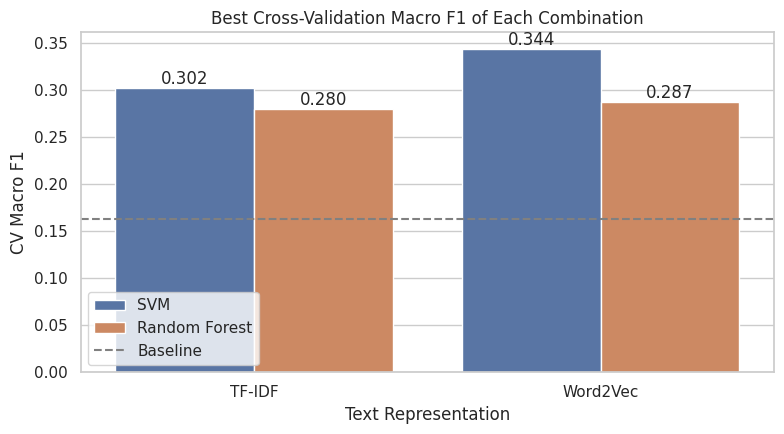

In [ ]:
tuningSummary = pd.DataFrame([
    {'Text Representation': representationName, 'Algorithm': modelName,
     'Best Hyperparameters': search.best_params_, 'CV Macro F1': round(search.best_score_, 3)}
    for (representationName, modelName), search in searchResults.items()
])
display(tuningSummary)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=tuningSummary, x='Text Representation', y='CV Macro F1', hue='Algorithm', ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')
ax.axhline(baselineScore, color='grey', linestyle='--', label='Baseline')
ax.set_title('Best Cross-Validation Macro F1 of Each Combination')
ax.legend()
plt.tight_layout()
plt.show()

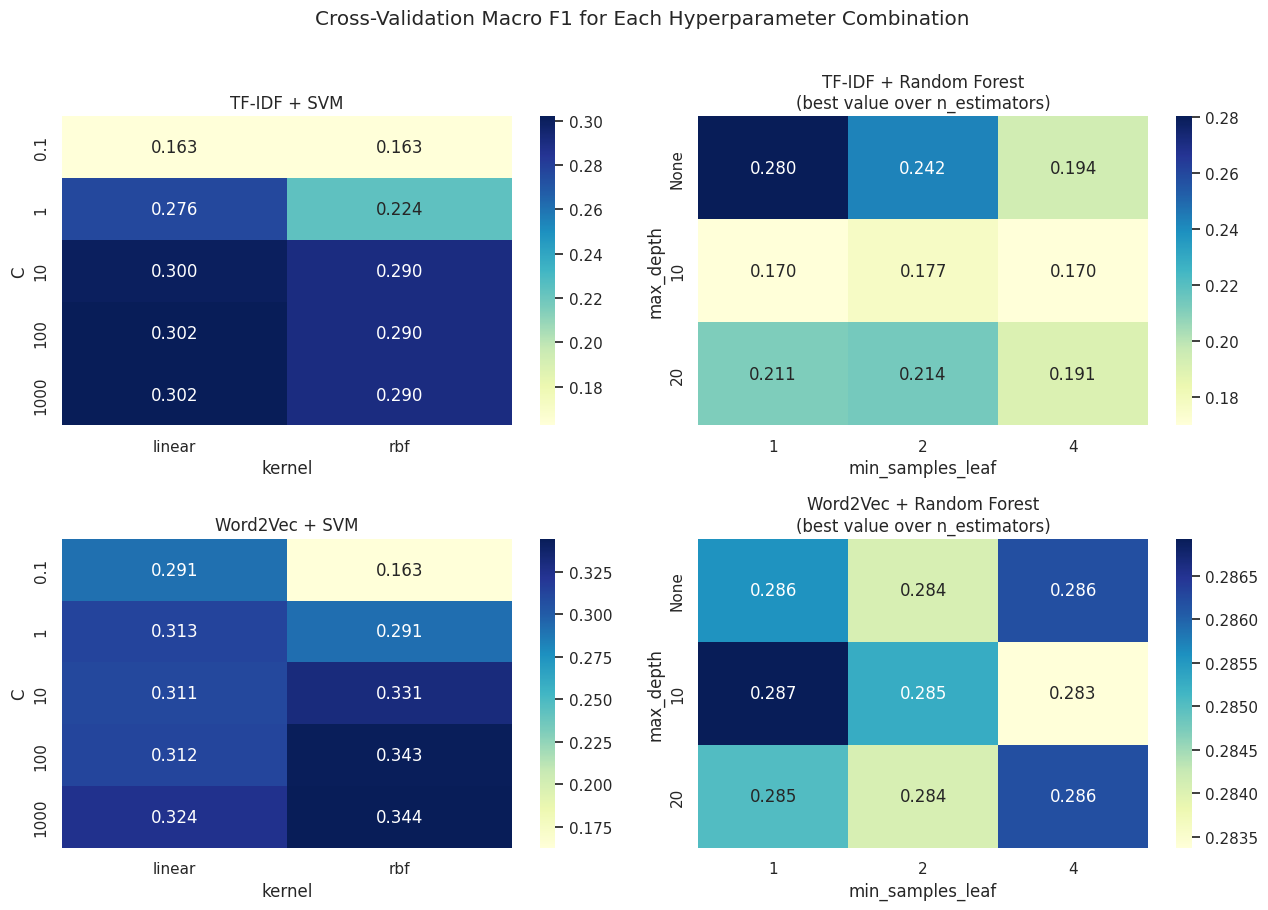

In [ ]:
heatmapParams = {'SVM': ('C', 'kernel'), 'Random Forest': ('max_depth', 'min_samples_leaf')}

def formatParam(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return 'None'
    if isinstance(value, (int, float, np.integer, np.floating)) and not isinstance(value, bool):
        return f'{float(value):g}'
    return str(value)

def plotGridHeatmap(search, paramGrid, rowParam, colParam, ax, title):
    results = pd.DataFrame(search.cv_results_)
    results['rowValue'] = results[f'param_{rowParam}'].apply(formatParam)
    results['colValue'] = results[f'param_{colParam}'].apply(formatParam)
    table = results.pivot_table(index='rowValue', columns='colValue', values='mean_test_score', aggfunc='max')
    table = table.reindex(index=[formatParam(v) for v in paramGrid[rowParam]],
                          columns=[formatParam(v) for v in paramGrid[colParam]])
    sns.heatmap(table, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax)
    ax.set_title(title)
    ax.set_ylabel(rowParam)
    ax.set_xlabel(colParam)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for rowIndex, representationName in enumerate(representations):
    for colIndex, modelName in enumerate(modelSettings):
        rowParam, colParam = heatmapParams[modelName]
        title = f'{representationName} + {modelName}'
        if modelName == 'Random Forest':
            title += '\n(best value over n_estimators)'
        plotGridHeatmap(searchResults[(representationName, modelName)], modelSettings[modelName][1],
                        rowParam, colParam, axes[rowIndex, colIndex], title)
plt.suptitle('Cross-Validation Macro F1 for Each Hyperparameter Combination', y=1.01)
plt.tight_layout()
plt.show()

The baseline CV macro F1 is 0.163. All four combinations are better, but the best scores (0.28 to 0.34) are only about double the baseline.
- **SVM is better than Random Forest** with both representations. The best is **Word2Vec + SVM** (RBF, C = 1000) with 0.344.
- C matters for SVM. With C = 0.1, three of four SVM settings give exactly 0.163 (the model predicts 5 for every review). The score rises with C and is flat after C = 10 (TF-IDF) or C = 100 (Word2Vec RBF).
- Best kernel: linear for TF-IDF, RBF for Word2Vec.
- Random Forest with TF-IDF needs deep trees: no depth limit gives 0.280, but max_depth = 10 drops to about 0.17. With Word2Vec, all combinations are 0.283-0.287, so the hyperparameters hardly matter.

In [ ]:
bestModels = {key: search.best_estimator_ for key, search in searchResults.items()}
print('Saved models:', list(bestModels.keys()))

Saved models: [('TF-IDF', 'SVM'), ('TF-IDF', 'Random Forest'), ('Word2Vec', 'SVM'), ('Word2Vec', 'Random Forest')]


## **6. Performance Evaluation**
I test the 4 tuned models on the test set, which was never used for training or tuning.

**Metrics:**
- Accuracy: share of correct ratings. It is misleading here, because always predicting 5 gets about 68%.
- Precision: when the model predicts a rating, how often it is right.
- Recall: of the reviews with a rating, how many the model finds.
- F1: combines precision and recall.

I use the **macro average** (plain average over the 5 ratings), so rating 2 counts as much as rating 5. I also add the baseline. I show the table from the task, then confusion matrices and the score of each rating. The test set has only 198 reviews (8 for rating 2), so scores can change a lot with a few reviews.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

testData = {'TF-IDF': xTestTfidf, 'Word2Vec': xTestW2v}
predictions = {}
resultRows = []

for (representationName, modelName), model in bestModels.items():
    yPred = model.predict(testData[representationName])
    predictions[(representationName, modelName)] = yPred
    resultRows.append({
        'Text Representation': representationName,
        'Machine Learning Algorithm': modelName,
        'Machine Learning Hyperparameter': str(searchResults[(representationName, modelName)].best_params_),
        'Accuracy': accuracy_score(yTest, yPred),
        'Precision (Macro)': precision_score(yTest, yPred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(yTest, yPred, average='macro', zero_division=0),
        'F1 (Macro)': f1_score(yTest, yPred, average='macro', zero_division=0),
    })

baselineModel = DummyClassifier(strategy='most_frequent').fit(xTrainTfidf, yTrain)
baselinePred = baselineModel.predict(xTestTfidf)
resultRows.append({
    'Text Representation': '-',
    'Machine Learning Algorithm': 'Baseline (always rating 5)',
    'Machine Learning Hyperparameter': '-',
    'Accuracy': accuracy_score(yTest, baselinePred),
    'Precision (Macro)': precision_score(yTest, baselinePred, average='macro', zero_division=0),
    'Recall (Macro)': recall_score(yTest, baselinePred, average='macro', zero_division=0),
    'F1 (Macro)': f1_score(yTest, baselinePred, average='macro', zero_division=0),
})

metricColumns = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1 (Macro)']
dfResults = pd.DataFrame(resultRows)
dfResults.round(3).style.highlight_max(subset=metricColumns, color='#cfe8cf')

,Text Representation,Machine Learning Algorithm,Machine Learning Hyperparameter,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,TF-IDF,SVM,"{'C': 100, 'kernel': 'linear'}",0.646000,0.309000,0.306000,0.301000
1,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}",0.712000,0.321000,0.272000,0.269000
2,Word2Vec,SVM,"{'C': 1000, 'kernel': 'rbf'}",0.697000,0.397000,0.315000,0.330000
3,Word2Vec,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}",0.702000,0.236000,0.253000,0.239000
4,-,Baseline (always rating 5),-,0.682000,0.136000,0.200000,0.162000


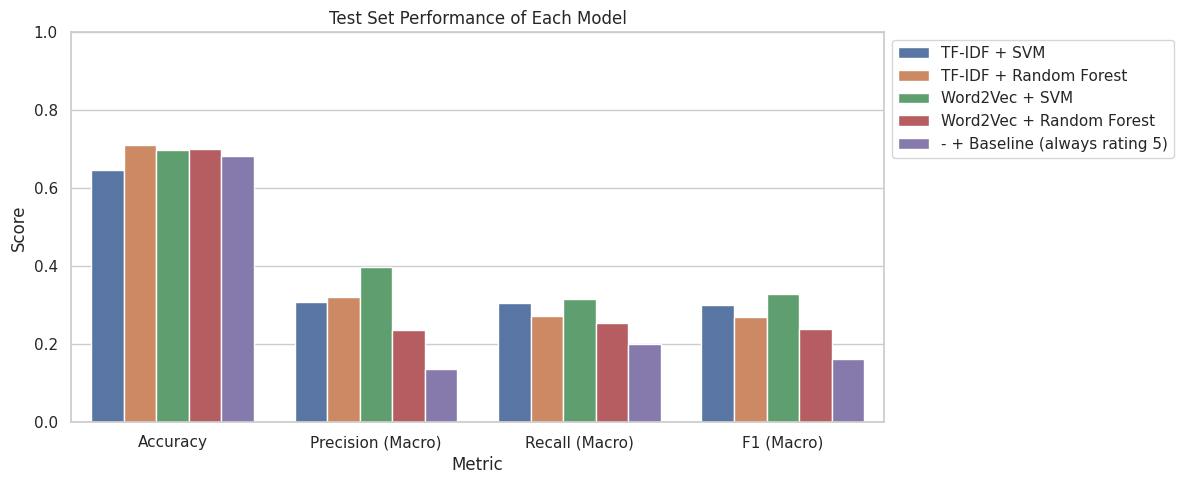

In [ ]:
resultLong = dfResults.copy()
resultLong['Model'] = resultLong['Text Representation'] + ' + ' + resultLong['Machine Learning Algorithm']
resultLong = resultLong.melt(id_vars='Model', value_vars=metricColumns, var_name='Metric', value_name='Score')

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=resultLong, x='Metric', y='Score', hue='Model', ax=ax)
ax.set_title('Test Set Performance of Each Model')
ax.set_ylim(0, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

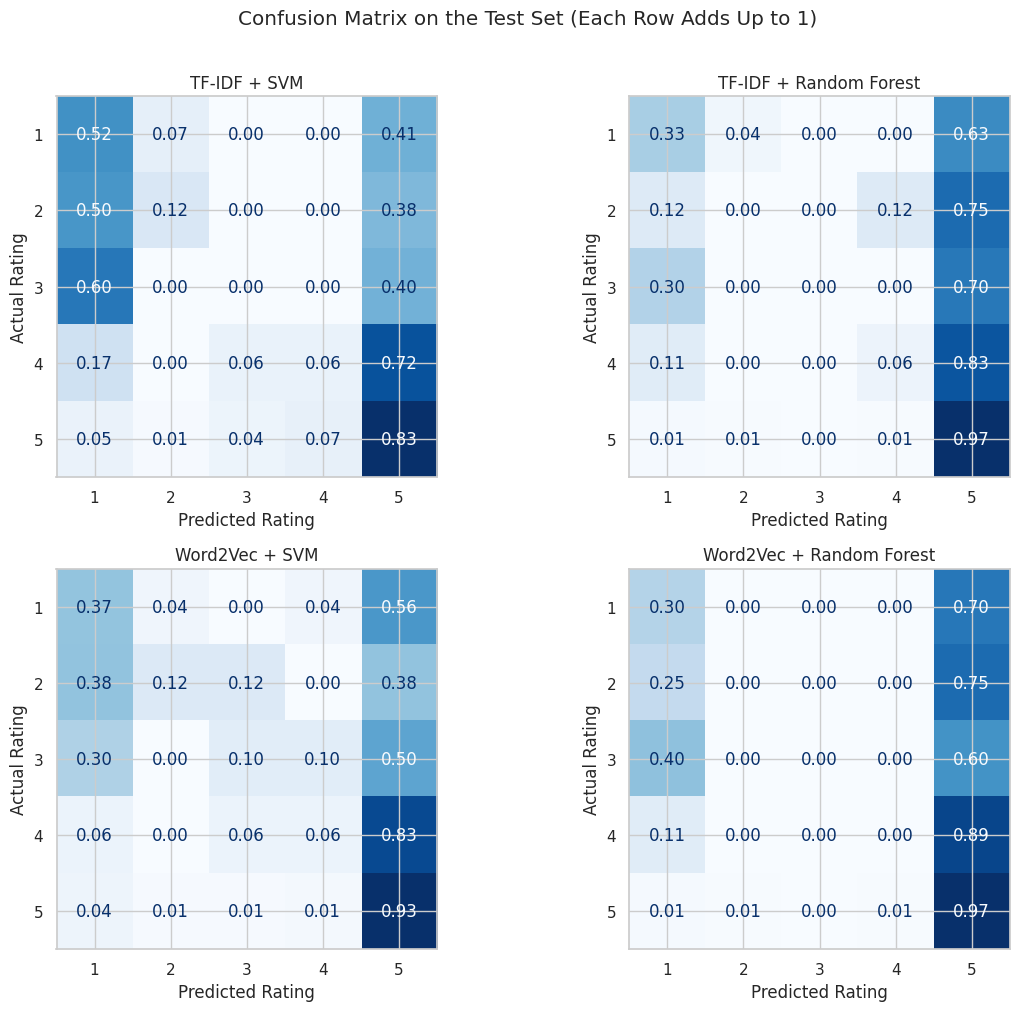

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, ((representationName, modelName), yPred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(yTest, yPred, labels=ratingOrder, normalize='true',
                                            values_format='.2f', cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{representationName} + {modelName}')
    ax.set_xlabel('Predicted Rating')
    ax.set_ylabel('Actual Rating')
plt.suptitle('Confusion Matrix on the Test Set (Each Row Adds Up to 1)', y=1.01)
plt.tight_layout()
plt.show()

Number of test reviews per rating: {1: np.int64(27), 2: np.int64(8), 3: np.int64(10), 4: np.int64(18), 5: np.int64(135)}


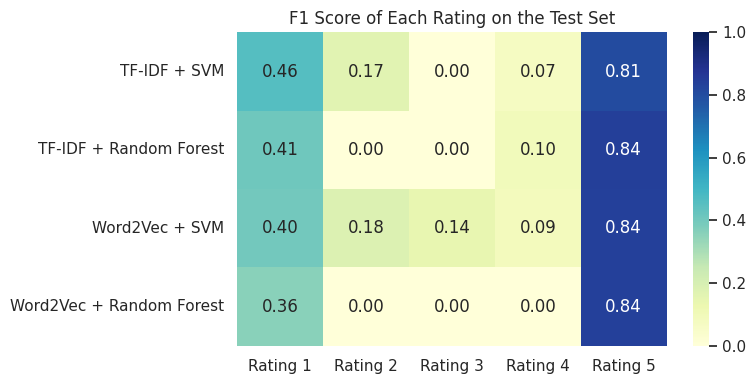

In [ ]:
from sklearn.metrics import classification_report

f1ByRating = {}
for (representationName, modelName), yPred in predictions.items():
    report = classification_report(yTest, yPred, labels=ratingOrder, output_dict=True, zero_division=0)
    f1ByRating[f'{representationName} + {modelName}'] = [report[str(rating)]['f1-score'] for rating in ratingOrder]

dfF1ByRating = pd.DataFrame(f1ByRating, index=[f'Rating {rating}' for rating in ratingOrder]).T
testSupport = pd.Series(yTest).value_counts().sort_index()
print('Number of test reviews per rating:', dict(testSupport))

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(dfF1ByRating, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
ax.set_title('F1 Score of Each Rating on the Test Set')
plt.tight_layout()
plt.show()

In [ ]:
comparisonRows = []
for (representationName, modelName), search in searchResults.items():
    comparisonRows.append({
        'Model': f'{representationName} + {modelName}',
        'CV Macro F1 (Train)': round(search.best_score_, 3),
        'Test Macro F1': round(dfResults.loc[(dfResults['Text Representation'] == representationName) &
                                             (dfResults['Machine Learning Algorithm'] == modelName), 'F1 (Macro)'].iloc[0], 3),
    })
dfComparison = pd.DataFrame(comparisonRows)
dfComparison['Difference'] = (dfComparison['Test Macro F1'] - dfComparison['CV Macro F1 (Train)']).round(3)
dfComparison

,Model,CV Macro F1 (Train),Test Macro F1,Difference
0,TF-IDF + SVM,0.302,0.301,-0.001
1,TF-IDF + Random Forest,0.280,0.269,-0.011
2,Word2Vec + SVM,0.344,0.330,-0.014
3,Word2Vec + Random Forest,0.287,0.239,-0.048


- Accuracy is misleading. Baseline accuracy is 0.682. TF-IDF + SVM (0.646) is lower, and the others are only 0.697 to 0.712. TF-IDF + Random Forest has the best accuracy but predicts 5 for almost every review, so its macro recall is only 0.272.
- Best model: **Word2Vec + SVM** (macro F1 0.330, precision 0.397, recall 0.315), then TF-IDF + SVM (0.301). The Random Forest models are weaker (0.269 and 0.239). All beat the baseline (0.162).
- CV vs test: close for three models (-0.001 to -0.014). Word2Vec + Random Forest drops 0.048, so it is the least stable.
- Per rating: rating 5 is easy (F1 0.81-0.84), rating 1 is second (0.36-0.46), and ratings 2, 3, and 4 almost fail (best F1 0.18, 0.14, and 0.10).
- Mistakes: rating 2 and 3 reviews are often predicted as 1, and rating 4 as 5 (72-89%). The models learned positive vs negative, but not the difference between neighbouring ratings.
- The test set is small (8 reviews for rating 2, 10 for rating 3), so a difference of about 0.03 can be noise.

**Conclusion:** Word2Vec + SVM is the best before any treatment, but all models lean toward rating 5, so I treat the imbalance in Question 7.

## **7. Handling Imbalanced Data**
Previously, all models leaned toward rating 5 (542 train reviews vs only 29 for rating 2), because always choosing the big class is the easiest way to score well. I try three treatments and train again:
1. Class weight: the data does not change, but a mistake on a rare rating costs more (balanced).
2. Random oversampling: copy random reviews of small ratings until all ratings have the same number. It is simple, but exact copies can overfit.
3. SMOTE: create new points between a small-rating review and its nearest neighbours. They are new, but may not match real text.

I do not use undersampling, because it would keep only about 145 of the 792 train reviews.

I change only the train data (the test set stays the same as in Question 6), and I resample inside cross validation (only the training part of each fold). Otherwise copies of one review would be in both training and validation, and the score would look too good. I use the same algorithms and hyperparameter values as in Question 5. I expect accuracy to go down and macro scores and recall of small ratings to go up.

After these three treatments, I try extra experiments by collecting more real minority reviews, back translation (paraphrasing small ratings with translation), stronger features from pretrained transformers, and grouping the ratings into 3 sentiment classes.

In [ ]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 12.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=e8754af3bf47cfac9904a811c9121f32ce449f40e68e127558a1da9ff1f4ad82
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


,Original,Random Oversampling,SMOTE
1,106,542,542
2,29,542,542
3,42,542,542
4,73,542,542
5,542,542,542


Class weights (balanced): {1: np.float64(1.49), 2: np.float64(5.46), 3: np.float64(3.77), 4: np.float64(2.17), 5: np.float64(0.29)}


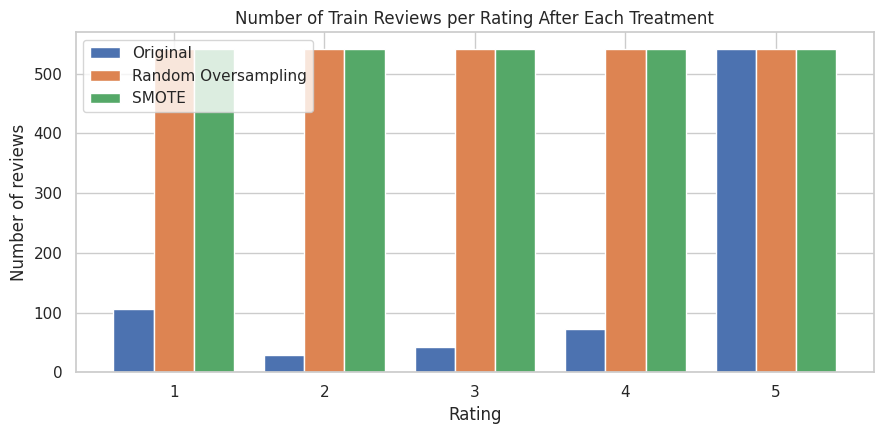

In [ ]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.utils.class_weight import compute_class_weight

countTable = pd.DataFrame({
    'Original': pd.Series(yTrain).value_counts().sort_index(),
    'Random Oversampling': pd.Series(RandomOverSampler(random_state=42).fit_resample(xTrainW2v, yTrain)[1]).value_counts().sort_index(),
    'SMOTE': pd.Series(SMOTE(random_state=42).fit_resample(xTrainW2v, yTrain)[1]).value_counts().sort_index(),
})
display(countTable)

classWeights = compute_class_weight('balanced', classes=np.array(ratingOrder), y=yTrain)
print('Class weights (balanced):', {rating: round(weight, 2) for rating, weight in zip(ratingOrder, classWeights)})

ax = countTable.plot(kind='bar', figsize=(9, 4.5), width=0.8)
ax.set_title('Number of Train Reviews per Rating After Each Treatment')
ax.set_xlabel('Rating')
ax.set_ylabel('Number of reviews')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline

treatments = {
    'Class Weight': {'sampler': 'passthrough', 'classWeight': 'balanced'},
    'Random Oversampling': {'sampler': RandomOverSampler(random_state=42), 'classWeight': None},
    'SMOTE': {'sampler': SMOTE(random_state=42), 'classWeight': None},
}

treatedSearches = {}

for treatmentName, setting in treatments.items():
    for representationName, xTrain in representations.items():
        for modelName, (baseModel, paramGrid) in modelSettings.items():
            model = clone(baseModel).set_params(class_weight=setting['classWeight'])
            pipeline = ImbPipeline([('sampler', setting['sampler']), ('model', model)])
            pipelineGrid = {f'model__{name}': values for name, values in paramGrid.items()}
            search = GridSearchCV(pipeline, pipelineGrid, scoring='f1_macro', cv=crossValidation, n_jobs=-1)
            search.fit(xTrain, yTrain)
            treatedSearches[(treatmentName, representationName, modelName)] = search
            bestParams = {name.replace('model__', ''): value for name, value in search.best_params_.items()}
            print(f'{treatmentName} | {representationName} + {modelName}')
            print(f'   Best CV macro F1: {search.best_score_:.3f}')
            print(f'   Best hyperparameters: {bestParams}')

Class Weight | TF-IDF + SVM
   Best CV macro F1: 0.332
   Best hyperparameters: {'C': 1, 'kernel': 'linear'}
Class Weight | TF-IDF + Random Forest
   Best CV macro F1: 0.329
   Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
Class Weight | Word2Vec + SVM
   Best CV macro F1: 0.335
   Best hyperparameters: {'C': 10, 'kernel': 'rbf'}
Class Weight | Word2Vec + Random Forest
   Best CV macro F1: 0.308
   Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 300}
Random Oversampling | TF-IDF + SVM
   Best CV macro F1: 0.357
   Best hyperparameters: {'C': 0.1, 'kernel': 'linear'}
Random Oversampling | TF-IDF + Random Forest
   Best CV macro F1: 0.343
   Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}
Random Oversampling | Word2Vec + SVM
   Best CV macro F1: 0.349
   Best hyperparameters: {'C': 0.1, 'kernel': 'rbf'}
Random Oversampling | Word2Vec + Random Forest
   Best CV macro F1: 0.327
   Bes

Before treatment, rating 5 has 542 train reviews and rating 2 only 29 (about 19 times fewer). Oversampling and SMOTE make every rating 542 reviews (train grows from 792 to 2,710). Class weight keeps 792 reviews but gives rating 2 a weight of 5.46 and rating 5 a weight of 0.29, so a mistake on rating 2 costs about 19 times more.

In [ ]:
def computeMetrics(yTrue, yPred):
    return {
        'Accuracy': accuracy_score(yTrue, yPred),
        'Precision (Macro)': precision_score(yTrue, yPred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(yTrue, yPred, average='macro', zero_division=0),
        'F1 (Macro)': f1_score(yTrue, yPred, average='macro', zero_division=0),
    }

runList = [('No Treatment', rep, model, search) for (rep, model), search in searchResults.items()]
runList += [(treatment, rep, model, search) for (treatment, rep, model), search in treatedSearches.items()]

allPredictions = {}
allRows = []
for treatmentName, representationName, modelName, search in runList:
    yPred = search.predict(testData[representationName])
    allPredictions[(treatmentName, representationName, modelName)] = yPred
    bestParams = {name.replace('model__', ''): value for name, value in search.best_params_.items()}
    row = {'Treatment': treatmentName, 'Text Representation': representationName, 'Algorithm': modelName,
           'Hyperparameter': str(bestParams), 'CV Macro F1': search.best_score_}
    row.update(computeMetrics(yTest, yPred))
    allRows.append(row)

treatmentOrder = ['No Treatment', 'Class Weight', 'Random Oversampling', 'SMOTE']
dfAllResults = pd.DataFrame(allRows)
dfAllResults['Treatment'] = pd.Categorical(dfAllResults['Treatment'], categories=treatmentOrder, ordered=True)
dfAllResults = dfAllResults.sort_values(['Text Representation', 'Algorithm', 'Treatment']).reset_index(drop=True)
dfAllResults['Model'] = dfAllResults['Text Representation'] + ' + ' + dfAllResults['Algorithm']

display(dfAllResults.drop(columns='Model').round(3).style.highlight_max(subset=['CV Macro F1'] + metricColumns, color='#cfe8cf'))

,Treatment,Text Representation,Algorithm,Hyperparameter,CV Macro F1,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,No Treatment,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}",0.280000,0.712000,0.321000,0.272000,0.269000
1,Class Weight,TF-IDF,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}",0.329000,0.596000,0.372000,0.323000,0.332000
2,Random Oversampling,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}",0.343000,0.712000,0.444000,0.371000,0.391000
3,SMOTE,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}",0.323000,0.697000,0.377000,0.362000,0.367000
4,No Treatment,TF-IDF,SVM,"{'C': 100, 'kernel': 'linear'}",0.302000,0.646000,0.309000,0.306000,0.301000
5,Class Weight,TF-IDF,SVM,"{'C': 1, 'kernel': 'linear'}",0.332000,0.626000,0.348000,0.340000,0.342000
6,Random Oversampling,TF-IDF,SVM,"{'C': 0.1, 'kernel': 'linear'}",0.357000,0.591000,0.358000,0.381000,0.360000
7,SMOTE,TF-IDF,SVM,"{'C': 1, 'kernel': 'linear'}",0.313000,0.626000,0.342000,0.351000,0.325000
8,No Treatment,Word2Vec,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}",0.287000,0.702000,0.236000,0.253000,0.239000
9,Class Weight,Word2Vec,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 300}",0.308000,0.672000,0.331000,0.293000,0.296000


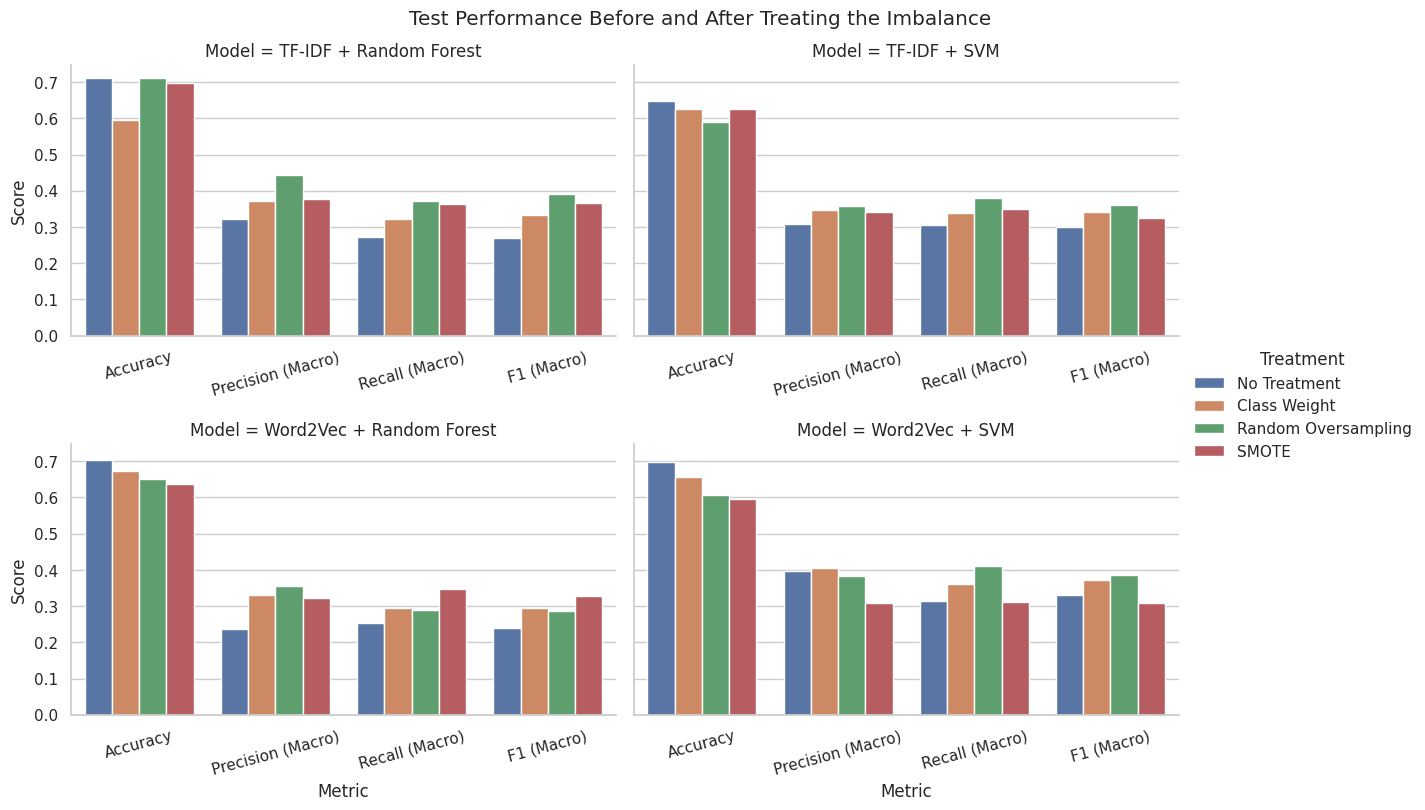

In [ ]:
longResults = dfAllResults.melt(id_vars=['Model', 'Treatment'], value_vars=metricColumns,
                                var_name='Metric', value_name='Score')

grid = sns.catplot(data=longResults, x='Metric', y='Score', hue='Treatment', hue_order=treatmentOrder,
                   col='Model', col_wrap=2, kind='bar', height=3.8, aspect=1.6)

for ax in grid.axes.flat:
    ax.tick_params(axis='x', labelbottom=True, rotation=15)

grid.figure.subplots_adjust(hspace=0.4)

grid.figure.suptitle('Test Performance Before and After Treating the Imbalance', y=1.02)
plt.show()

**Did the treatments change the performance? Yes.**
- On the test set, 11 of 12 treated models have a better macro F1 than the same model without treatment (exception: Word2Vec + SVM with SMOTE, 0.330 to 0.309). In CV, 10 of 12 are better.
- The average test macro F1 goes from 0.285 (none) to 0.335 (class weight), 0.356 (random oversampling), and 0.333 (SMOTE).
- The accuracy average goes from 0.689 to about 0.64, because rating 5 is predicted less. For example, Word2Vec + SVM goes from 0.697 to 0.606 with oversampling, but its macro recall goes from 0.315 to 0.411.

Which treatment?
- Random oversampling is the best on average (best test F1 for 3 of 4 models).
- Class weight is second and the simplest, and it improves all 4 models on the test set.
- SMOTE is unstable, it helps Word2Vec + Random Forest a lot (CV 0.287 to 0.362) but not Word2Vec + SVM. Maybe new points between neighbours fall in the wrong area for in-between ratings like 4.

Random Forest gains the most (it was weakest), and Word2Vec + SVM gains the least (it was already best). The best hyperparameters changed. SVM no longer needs a very large C (the "always 5" shortcut is gone), so C = 0.1 works with oversampling and C = 1 or 10 with class weight.

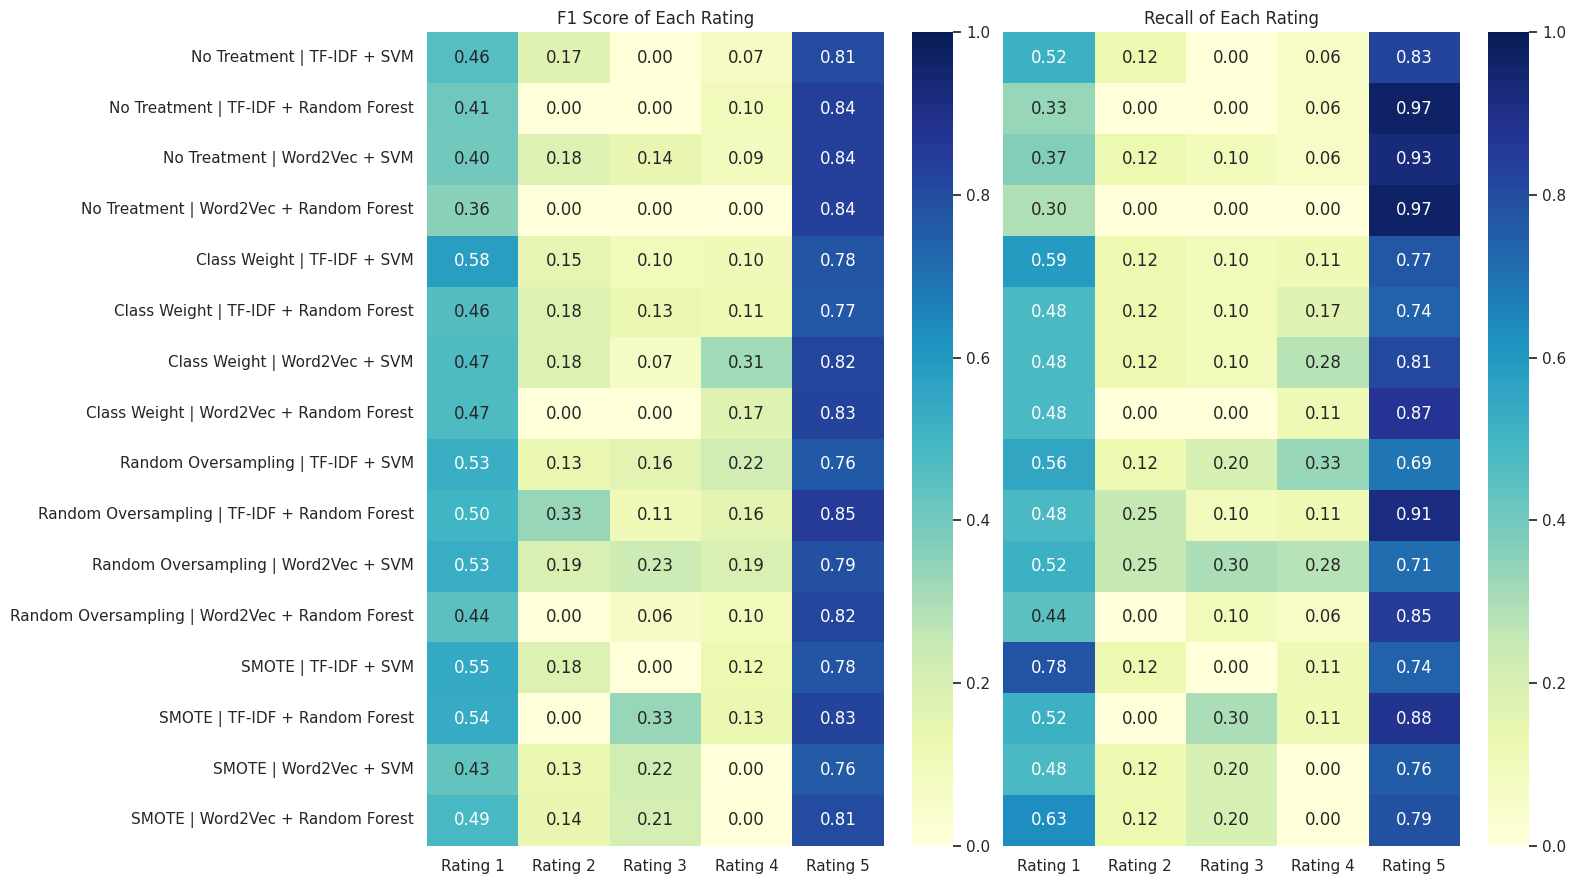

In [ ]:
from sklearn.metrics import classification_report

perRatingF1 = {}
perRatingRecall = {}
for key, yPred in allPredictions.items():
    report = classification_report(yTest, yPred, labels=ratingOrder, output_dict=True, zero_division=0)
    label = f'{key[0]} | {key[1]} + {key[2]}'
    perRatingF1[label] = [report[str(rating)]['f1-score'] for rating in ratingOrder]
    perRatingRecall[label] = [report[str(rating)]['recall'] for rating in ratingOrder]

ratingLabels = [f'Rating {rating}' for rating in ratingOrder]
dfPerRatingF1 = pd.DataFrame(perRatingF1, index=ratingLabels).T
dfPerRatingRecall = pd.DataFrame(perRatingRecall, index=ratingLabels).T

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
sns.heatmap(dfPerRatingF1, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('F1 Score of Each Rating')
sns.heatmap(dfPerRatingRecall, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Recall of Each Rating')
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

Best model by CV macro F1: SMOTE | Word2Vec + Random Forest
   CV macro F1: 0.362 | Test accuracy: 0.636 | Test macro F1: 0.329
   Hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
Best model by test macro F1: Random Oversampling | TF-IDF + Random Forest
   CV macro F1: 0.343 | Test accuracy: 0.712 | Test macro F1: 0.391
   Hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}
Best model before treatment: No Treatment | Word2Vec + SVM
   CV macro F1: 0.344 | Test accuracy: 0.697 | Test macro F1: 0.330
   Hyperparameters: {'C': 1000, 'kernel': 'rbf'}


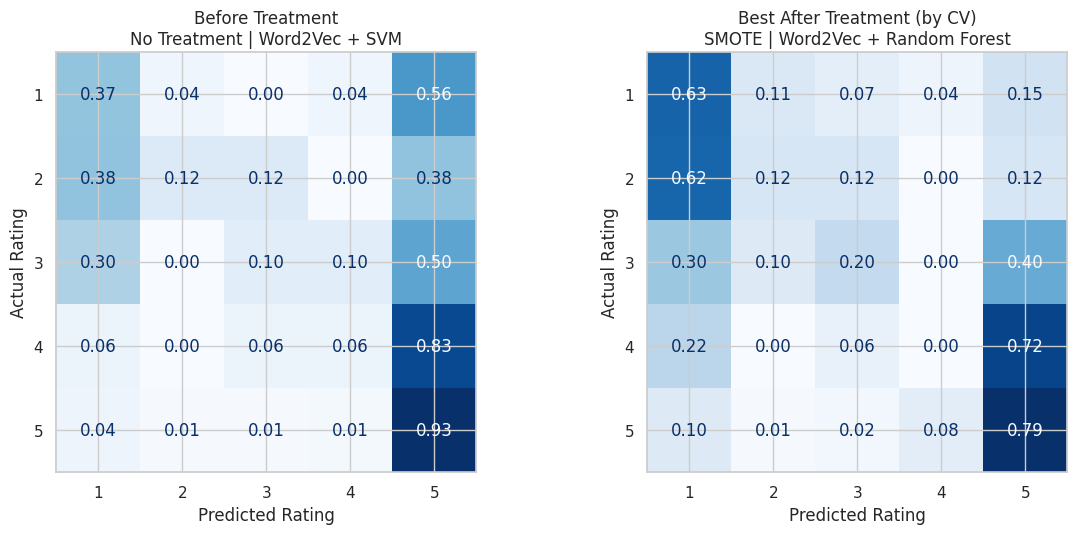

In [ ]:
bestByCv = dfAllResults.loc[dfAllResults['CV Macro F1'].idxmax()]
bestByTest = dfAllResults.loc[dfAllResults['F1 (Macro)'].idxmax()]
originalBest = dfAllResults[dfAllResults['Treatment'] == 'No Treatment'].sort_values('CV Macro F1').iloc[-1]

for title, row in [('Best model by CV macro F1', bestByCv), ('Best model by test macro F1', bestByTest),
                   ('Best model before treatment', originalBest)]:
    print(f'{title}: {row["Treatment"]} | {row["Model"]}')
    print(f'   CV macro F1: {row["CV Macro F1"]:.3f} | Test accuracy: {row["Accuracy"]:.3f} | Test macro F1: {row["F1 (Macro)"]:.3f}')
    print(f'   Hyperparameters: {row["Hyperparameter"]}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, row) in zip(axes, [('Before Treatment', originalBest), ('Best After Treatment (by CV)', bestByCv)]):
    key = (str(row['Treatment']), row['Text Representation'], row['Algorithm'])
    ConfusionMatrixDisplay.from_predictions(yTest, allPredictions[key], labels=ratingOrder, normalize='true',
                                            values_format='.2f', cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{title}\n{key[0]} | {key[1]} + {key[2]}')
    ax.set_xlabel('Predicted Rating')
    ax.set_ylabel('Actual Rating')
plt.tight_layout()
plt.show()

- Rating 5 recall goes from 0.83-0.97 to 0.69-0.91, but F1 stays high (0.76-0.85).
- Rating 1 gains F1 score that goes from 0.36-0.46 to 0.43-0.58.
- Ratings 3 and 4 are found more often, Word2Vec + SVM with class weight has a rating 4 F1 of 0.31 (before 0.09), and with oversampling its rating 3 recall goes from 0.10 to 0.30. With SMOTE, both Word2Vec models still have recall 0.00 for rating 4.
- Rating 2 barely changes, the recall is mostly 0.12 (1 of 8) and at best 0.25 (2 of 8).

Confusion matrix: compared with Word2Vec + SVM before treatment, SMOTE + Word2Vec + Random Forest finds rating 1 more often (0.37 to 0.63) and rating 3 too (0.10 to 0.20), but rating 5 drops from 0.93 to 0.79. 62% of rating 2 reviews are now predicted as 1 (before 38%). Negative reviews land on the correct side more often, but close ratings are still not separated.

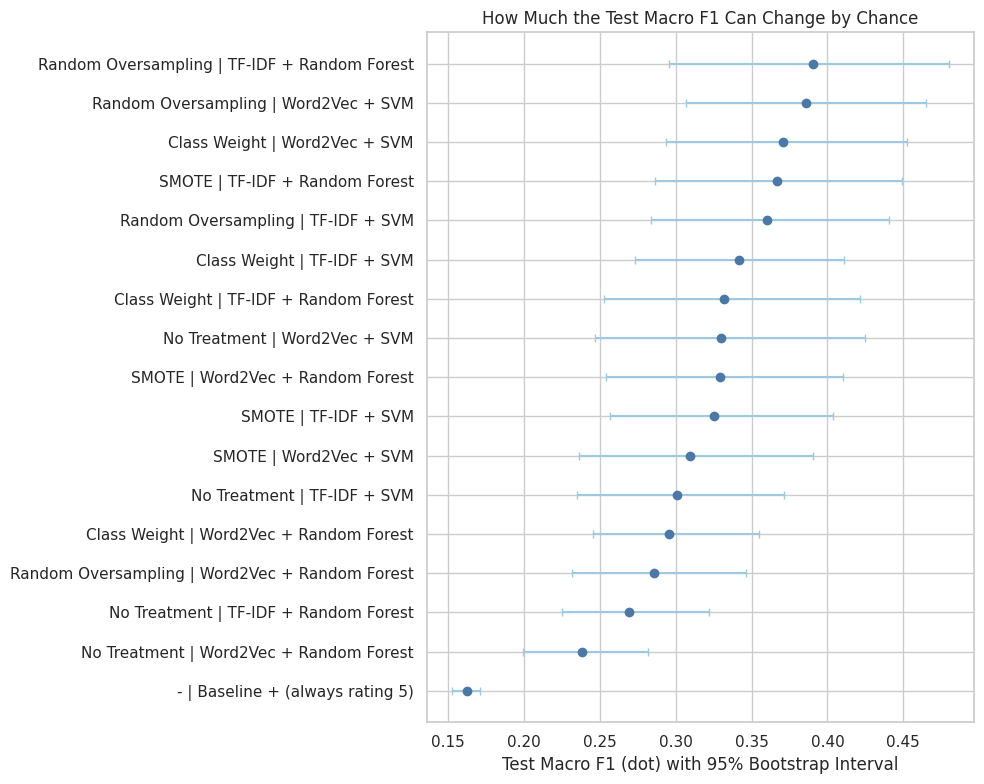

In [ ]:
def bootstrapMacroF1(yTrue, yPred, rounds=500, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(rounds):
        index = rng.integers(0, len(yTrue), len(yTrue))
        scores.append(f1_score(yTrue[index], yPred[index], average='macro', labels=ratingOrder, zero_division=0))
    return np.percentile(scores, [2.5, 97.5])

bootstrapRows = []
for key, yPred in list(allPredictions.items()) + [(('-', 'Baseline', '(always rating 5)'), baselinePred)]:
    yPred = np.asarray(yPred)
    lower, upper = bootstrapMacroF1(yTest, yPred)
    bootstrapRows.append({'Model': f'{key[0]} | {key[1]} + {key[2]}',
                          'F1': f1_score(yTest, yPred, average='macro', labels=ratingOrder, zero_division=0),
                          'Lower': lower, 'Upper': upper})
dfBootstrap = pd.DataFrame(bootstrapRows).sort_values('F1').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 8))
errorLow = np.clip(dfBootstrap['F1'] - dfBootstrap['Lower'], 0, None)
errorHigh = np.clip(dfBootstrap['Upper'] - dfBootstrap['F1'], 0, None)
ax.errorbar(dfBootstrap['F1'], range(len(dfBootstrap)), xerr=[errorLow, errorHigh],
            fmt='o', color='#4c78a8', ecolor='#9ecae1', capsize=3)
ax.set_yticks(range(len(dfBootstrap)))
ax.set_yticklabels(dfBootstrap['Model'])
ax.set_xlabel('Test Macro F1 (dot) with 95% Bootstrap Interval')
ax.set_title('How Much the Test Macro F1 Can Change by Chance')
plt.tight_layout()
plt.show()

With 500 bootstrap resamples of the test set, the 95% interval is about ±0.09 per model. All models are clearly above the baseline (0.162), but the top models overlap, so a difference below about 0.05 is not clear. Still, the 7 best models are all treated, and three of the four untreated models are in the bottom five.

**The Finalists**

| Model | CV F1 | Test accuracy | Test precision | Test recall | Test F1 |
|---|---|---|---|---|---|
| No treatment, Word2Vec + SVM | 0.344 | 0.697 | 0.397 | 0.315 | 0.330 |
| Random oversampling, TF-IDF + Random Forest | 0.343 | 0.712 | 0.444 | 0.371 | 0.391 |
| Random oversampling, Word2Vec + SVM | 0.349 | 0.606 | 0.382 | 0.411 | 0.386 |
| SMOTE, Word2Vec + Random Forest | 0.362 | 0.636 | 0.322 | 0.348 | 0.329 |

   **Best model with TF-IDF and Word2Vec: random oversampling + Word2Vec + SVM (RBF kernel, C = 0.1).**
- Its test F1 (0.386) is almost the same as the best (0.391), well within the uncertainty, and it has the best macro recall (0.411).
- It is the most balanced across ratings (recall for ratings 1 to 5: 0.52, 0.25, 0.30, 0.28, 0.71). The best-F1 model has only 0.10 and 0.11 for ratings 3 and 4.
- It has a good CV score (0.349) and was also the best model before treatment. The best-CV model (SMOTE + Word2Vec + Random Forest, 0.362) has a test F1 of only 0.329 and never finds rating 4.

**Conclusion:** Treating the imbalance helps: the models notice the small ratings, at some cost in accuracy, and random oversampling is the most reliable. But the model is still weak (best macro F1 about 0.39, recall of ratings 2 to 4 at most 0.33). The likely reasons are few reviews for ratings 2 to 4, neighbouring ratings that look alike, short texts, and Word2Vec trained on only about 800 reviews. I test three possible improvements more minority data, stronger features from pretrained transformers, and grouping into 3 classes.

### **Collecting More Minority Data**
Another way to handle imbalance is to collect more real reviews of the rare ratings. I scraped more reviews for ratings 2, 3, and 4 (the scraping function is turned off, and the saved CSV is used), removed reviews that are already in the first dataset, and kept English reviews with at least 4 words. I add them to the train set only, so the test set stays the same. TF-IDF and Word2Vec are trained again on the new train set.

In [ ]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 8.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=3fe4a073dc2acca42e97763b5fe2b9fe424e9008f0dfa30afc5a2d8efa8d34a2
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


In [ ]:
from google_play_scraper import reviews, Sort
import time

extraCsvPath = '/content/drive/MyDrive/TM/netflixExtraMinority.csv'

def scrapeExtraMinority(perRating=500):
    extraRows = []
    for star in [2, 3, 4]:
        token = None
        collected = 0
        while collected < perRating:
            batch, token = reviews(
                'com.netflix.mediaclient', lang='en', country='us',
                sort=Sort.NEWEST, count=200, filter_score_with=star,
                continuation_token=token)
            if not batch:
                break
            extraRows.extend(batch)
            collected += len(batch)
            if token is None:
                break
            time.sleep(1)
        print(f'Star {star}: {collected} reviews')
    pd.DataFrame(extraRows)[['content', 'score']].to_csv(extraCsvPath, index=False)

# scraping is turned off, the saved csv in drive is used instead
# scrapeExtraMinority()

In [ ]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

def isEnglish(text):
    try:
        return detect(text) == 'en'
    except Exception:
        return False

dfExtra = pd.read_csv('/content/drive/MyDrive/TM/netflixExtraMinority.csv')
dfExtra = dfExtra.drop_duplicates(subset='content').dropna(subset=['content'])
dfExtra = dfExtra[~dfExtra['content'].isin(dfReviews['content'])]
dfExtra = dfExtra[dfExtra['content'].str.split().str.len() >= 4]
dfExtra = dfExtra[dfExtra['content'].apply(isEnglish)].reset_index(drop=True)
print(dfExtra['score'].value_counts().sort_index())

score
2    452
3    368
4    292
Name: count, dtype: int64


In [ ]:
dfExtraPrep = dfExtra[['content', 'score']].copy()
dfExtraPrep['tokens'] = dfExtraPrep['content'].apply(preprocessReview)
dfExtraPrep['cleanText'] = dfExtraPrep['tokens'].apply(' '.join)

In [ ]:
emptyMaskExtra = dfExtraPrep['tokens'].str.len() == 0
dfExtraClean = dfExtraPrep.loc[~emptyMaskExtra].reset_index(drop=True)
print('Extra reviews after removing empty ones:', len(dfExtraClean))
print(dfExtraClean['score'].value_counts().sort_index())

Extra reviews after removing empty ones: 1111
score
2    452
3    368
4    291
Name: count, dtype: int64


In [ ]:
dfTrainExtra = pd.concat([dfTrain, dfExtraClean[dfTrain.columns]], ignore_index=True)
yTrainExtra = dfTrainExtra['score'].values

print('Train size before:', len(dfTrain), '| after:', len(dfTrainExtra))
print('Test size (unchanged):', len(dfTest))
print(pd.DataFrame({
    'Before': dfTrain['score'].value_counts().sort_index(),
    'After': dfTrainExtra['score'].value_counts().sort_index(),
}))

Train size before: 792 | after: 1903
Test size (unchanged): 198
       Before  After
score               
1         106    106
2          29    481
3          42    410
4          73    364
5         542    542


In [ ]:
tfidfVectorizerExtra = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
xTrainTfidfExtra = tfidfVectorizerExtra.fit_transform(dfTrainExtra['cleanText'])
xTestTfidfExtra = tfidfVectorizerExtra.transform(dfTest['cleanText'])

w2vModelExtra = Word2Vec(sentences=dfTrainExtra['tokens'].tolist(), vector_size=100, window=5,
                         min_count=2, sg=1, epochs=100, seed=42, workers=1)

def getAverageVectorExtra(tokenList):
    vectors = [w2vModelExtra.wv[token] for token in tokenList if token in w2vModelExtra.wv.key_to_index]
    if not vectors:
        return np.zeros(w2vModelExtra.vector_size)
    return np.mean(vectors, axis=0)

xTrainW2vExtra = np.array([getAverageVectorExtra(t) for t in dfTrainExtra['tokens']])
xTestW2vExtra = np.array([getAverageVectorExtra(t) for t in dfTest['tokens']])

print('TF-IDF train shape:', xTrainTfidfExtra.shape)
print('Word2Vec train shape:', xTrainW2vExtra.shape)
print('Vocabulary size:', len(w2vModelExtra.wv))

TF-IDF train shape: (1903, 2843)
Word2Vec train shape: (1903, 100)
Vocabulary size: 1408


In [ ]:
extraTreatments = {'Extra Data': None, 'Extra Data + Class Weight': 'balanced'}
extraTrainData = {'TF-IDF': xTrainTfidfExtra, 'Word2Vec': xTrainW2vExtra}
extraTestData = {'TF-IDF': xTestTfidfExtra, 'Word2Vec': xTestW2vExtra}

extraSearches = {}
for treatmentName, classWeight in extraTreatments.items():
    for representationName, xTrain in extraTrainData.items():
        for modelName, (baseModel, paramGrid) in modelSettings.items():
            model = clone(baseModel).set_params(class_weight=classWeight)
            search = GridSearchCV(model, paramGrid, scoring='f1_macro', cv=crossValidation, n_jobs=-1)
            search.fit(xTrain, yTrainExtra)
            extraSearches[(treatmentName, representationName, modelName)] = search
            print(f'{treatmentName} | {representationName} + {modelName}')
            print(f'   Best CV macro F1: {search.best_score_:.3f}')
            print(f'   Best hyperparameters: {search.best_params_}')

Extra Data | TF-IDF + SVM
   Best CV macro F1: 0.359
   Best hyperparameters: {'C': 10, 'kernel': 'rbf'}
Extra Data | TF-IDF + Random Forest
   Best CV macro F1: 0.339
   Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Extra Data | Word2Vec + SVM
   Best CV macro F1: 0.371
   Best hyperparameters: {'C': 1000, 'kernel': 'linear'}
Extra Data | Word2Vec + Random Forest
   Best CV macro F1: 0.352
   Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}
Extra Data + Class Weight | TF-IDF + SVM
   Best CV macro F1: 0.385
   Best hyperparameters: {'C': 1, 'kernel': 'linear'}
Extra Data + Class Weight | TF-IDF + Random Forest
   Best CV macro F1: 0.391
   Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}
Extra Data + Class Weight | Word2Vec + SVM
   Best CV macro F1: 0.390
   Best hyperparameters: {'C': 1, 'kernel': 'rbf'}
Extra Data + Class Weight | Word2Vec + Random Forest
   Best CV mac

In [ ]:
extraPredictions = {}
extraRows = []
for (treatmentName, representationName, modelName), search in extraSearches.items():
    yPred = search.predict(extraTestData[representationName])
    extraPredictions[(treatmentName, representationName, modelName)] = yPred
    row = {'Treatment': treatmentName, 'Text Representation': representationName, 'Algorithm': modelName,
           'Hyperparameter': str(search.best_params_), 'CV Macro F1': search.best_score_}
    row.update(computeMetrics(yTest, yPred))
    extraRows.append(row)

dfExtraResults = pd.DataFrame(extraRows)
display(dfExtraResults.round(3).style.highlight_max(subset=['CV Macro F1'] + metricColumns, color='#cfe8cf'))

print(f'Best test macro F1 with extra data: {dfExtraResults["F1 (Macro)"].max():.3f}')

,Treatment,Text Representation,Algorithm,Hyperparameter,CV Macro F1,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Extra Data,TF-IDF,SVM,"{'C': 10, 'kernel': 'rbf'}",0.359000,0.551000,0.453000,0.344000,0.301000
1,Extra Data,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}",0.339000,0.586000,0.237000,0.331000,0.258000
2,Extra Data,Word2Vec,SVM,"{'C': 1000, 'kernel': 'linear'}",0.371000,0.510000,0.382000,0.375000,0.301000
3,Extra Data,Word2Vec,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}",0.352000,0.566000,0.281000,0.321000,0.244000
4,Extra Data + Class Weight,TF-IDF,SVM,"{'C': 1, 'kernel': 'linear'}",0.385000,0.561000,0.367000,0.342000,0.319000
5,Extra Data + Class Weight,TF-IDF,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}",0.391000,0.611000,0.384000,0.387000,0.348000
6,Extra Data + Class Weight,Word2Vec,SVM,"{'C': 1, 'kernel': 'rbf'}",0.390000,0.551000,0.356000,0.419000,0.359000
7,Extra Data + Class Weight,Word2Vec,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 100}",0.377000,0.485000,0.295000,0.316000,0.262000


Best test macro F1 with extra data: 0.359


Collecting more data did not clearly improve the test result. Without class weight, the test macro F1 is 0.24-0.30. With class weight it is 0.26-0.36, and the best is Word2Vec + SVM (0.359). The best earlier model is about 0.39, so the extra data is not better. Because the test uncertainty is about ±0.09, this means there is no clear difference, not that it is worse. One possible reason is that the new reviews were searched by rating, so their style may differ from the random first sample, but I cannot confirm this.

### **Transformer Features with More Data**

The best score so far is about 0.39 with TF-IDF and Word2Vec. In this last experiment I use features from pretrained models: sentence embeddings (mpnet and bge), sentiment probabilities (RoBERTa), and star probabilities (nlptown BERT, which predicts 1-5 stars). They were not trained on Netflix reviews, so the test set does not leak.

I add real minority reviews to the train set only (389, 504, 431, 396, and 1,394 reviews for ratings 1-5) and remove any review that is also in the test set. I compare no balancing, class weight, and back translation (paraphrase with German, French, and Spanish). Validation folds use only original reviews, grouped by source, so paraphrases do not leak between folds. I use only SVM, because Random Forest was lower in every earlier run, and I choose models by CV macro F1, not by the test set.

In [ ]:
!pip install -q emoji

In [ ]:
import os, re, unicodedata
from functools import lru_cache
from itertools import groupby, product

import numpy as np
import pandas as pd
import nltk
import emoji
from google.colab import drive
from nltk import pos_tag
from nltk.corpus import stopwords, wordnet, words
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split

for resourceName in ['stopwords', 'wordnet', 'words', 'omw-1.4', 'averaged_perceptron_tagger',
                     'averaged_perceptron_tagger_eng']:
    nltk.download(resourceName, quiet=True)

drive.mount('/content/drive')
csvPath = '/content/drive/MyDrive/TM/netflixReviews.csv'
dfReviews = pd.read_csv(csvPath)
dfReviews['content'] = dfReviews['content'].astype(str)

stopWords = set(stopwords.words('english'))
negationWords = {word for word in stopWords if word in ('no', 'not', 'nor') or word.endswith("n't")}

englishVocab = {word.lower() for word in words.words()}
brandTerms = {'netflix', 'youtube', 'disney', 'hulu', 'hbo', 'amazon', 'prime', 'samsung', 'roku',
              'chromecast', 'android', 'iphone', 'ios', 'wifi', 'tv', 'hd', 'ui', 'ipad', 'google',
              'app', 'apps', 'ott', 'vpn', 'anytime', 'etc', 'others'}

@lru_cache(maxsize=None)
def isStandardWord(word):
    if len(word) == 1:
        return word in ('a', 'i')
    if word in stopWords or word in englishVocab or word in brandTerms:
        return True
    if "'" in word:
        return isStandardWord(word.split("'")[0])
    return len(wordnet.synsets(word)) > 0

def joinSpacedLetters(text):
    return re.sub(r'\b[a-z](?:[\s.]+[a-z]){2,}\b', lambda match: re.sub(r'[\s.]+', '', match.group(0)), text)

def basicClean(text):
    text = unicodedata.normalize('NFKC', text).lower()
    text = text.replace('\u2019', "'").replace('\u2018', "'").replace('\ufe0f', '')
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub('[\U0001F3FB-\U0001F3FF]', '', text)
    return joinSpacedLetters(text)

emojiGroups = {
    'good': '👍👌👏🙌💯🔥',
    'love': '❤♥😍🥰😘💕💖💗💙💜💛💚😻',
    'happy': '😊😃😄😁😀🙂☺',
    'funny': '😂🤣😆',
    'sad': '😭😢😞😔☹🙁',
    'angry': '😡😠🤬😤',
    'bad': '👎🤮💩',
    'thanks': '🙏',
}
emojiMeaning = {char: meaning for meaning, chars in emojiGroups.items() for char in chars}

def convertEmoji(text):
    result = []
    for char in text:
        if char in emojiMeaning:
            result.append(f' {emojiMeaning[char]} ')
        elif char in emoji.EMOJI_DATA:
            name = emoji.demojize(char, delimiters=(' ', ' ')).replace('_', ' ')
            result.append(' ' + re.sub(r'\b(face|with|of)\b', ' ', name) + ' ')
        else:
            result.append(char)
    return ''.join(result)

contractionMap = {
    "can't": 'cannot', "won't": 'will not', "shan't": 'shall not', "ain't": 'is not', "let's": 'let us',
    "i'm": 'i am', "it's": 'it is', "that's": 'that is', "what's": 'what is', "there's": 'there is',
    "here's": 'here is', "he's": 'he is', "she's": 'she is', "who's": 'who is',
}
suffixRules = [("n't", ' not'), ("'re", ' are'), ("'ve", ' have'), ("'ll", ' will'), ("'d", ' would'), ("'m", ' am')]
slangMap = {
    'u': 'you', 'ur': 'your', 'r': 'are', 'pls': 'please', 'plz': 'please', 'thx': 'thanks', 'thanx': 'thanks',
    'gonna': 'going to', 'wanna': 'want to', 'gotta': 'got to', 'gud': 'good', 'bcz': 'because', 'coz': 'because',
    'cuz': 'because', 'bcoz': 'because', 'ok': 'okay', 'tbh': 'to be honest', 'omg': 'oh my god', 'lol': 'funny',
    'luv': 'love', 'awsome': 'awesome', 'dont': 'do not', 'cant': 'cannot', 'wont': 'will not', 'im': 'i am',
    'ive': 'i have', 'didnt': 'did not', 'doesnt': 'does not', 'isnt': 'is not', 'wasnt': 'was not',
    'couldnt': 'could not', 'youre': 'you are', 'thats': 'that is',
}
slangMap.update({'idk': 'i do not know', 'vry': 'very', 'veri': 'very', 'usefull': 'useful', 'thru': 'through'})

def normalizeWord(match):
    word = match.group(0).strip("'")
    if word in contractionMap:
        return contractionMap[word]
    if word in slangMap:
        return slangMap[word]
    for suffix, replacement in suffixRules:
        if word.endswith(suffix) and len(word) > len(suffix):
            return word[:-len(suffix)] + replacement
    if word.endswith("'s"):
        return word[:-2]
    return word

def removeNonLetters(text):
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def fixStretched(word):
    groups = [(char, len(list(items))) for char, items in groupby(word)]
    options = [[2, 1] if count >= 3 else [count] for _, count in groups]
    candidates = [''.join(char * size for (char, _), size in zip(groups, sizes)) for sizes in product(*options)]
    for candidate in candidates:
        if isStandardWord(candidate):
            return candidate
    return candidates[0]

def fixAllStretched(text):
    return ' '.join(fixStretched(word) if re.search(r'(.)\1{2,}', word) else word for word in text.split())

lemmatizer = WordNetLemmatizer()

def getWordnetPos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    if tag.startswith('V'):
        return wordnet.VERB
    if tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

keepWords = negationWords | {'cannot'}

def lemmatizeText(text):
    tokens = text.split()
    return [(token, lemmatizer.lemmatize(token, getWordnetPos(tag))) for token, tag in pos_tag(tokens)]

def preprocessReview(text):
    text = basicClean(text)
    text = convertEmoji(text)
    text = re.sub(r"[a-z']+", normalizeWord, text)
    text = removeNonLetters(text)
    text = fixAllStretched(text)
    return [lemma for token, lemma in lemmatizeText(text)
            if len(lemma) > 1 and (token in keepWords or (token not in stopWords and lemma not in stopWords))]

dfPrep = dfReviews[['content', 'score']].copy()
dfPrep['tokens'] = dfPrep['content'].apply(preprocessReview)
dfPrep['cleanText'] = dfPrep['tokens'].apply(' '.join)
dfClean = dfPrep.loc[dfPrep['tokens'].str.len() > 0].reset_index(drop=True)

dfTrain, dfTest = train_test_split(dfClean, test_size=0.2, random_state=42, stratify=dfClean['score'])
dfTrain = dfTrain.reset_index(drop=True)
dfTest = dfTest.reset_index(drop=True)

dfTrain[['content', 'score']].to_csv('/content/drive/MyDrive/TM/tmTrain.csv', index=False)
dfTest[['content', 'score']].to_csv('/content/drive/MyDrive/TM/tmTest.csv', index=False)
print('Reviews after cleaning:', len(dfClean))
print('Train size:', len(dfTrain), '| Test size:', len(dfTest))
print('Train per rating:', dfTrain['score'].value_counts().sort_index().to_dict())
print('Test per rating:', dfTest['score'].value_counts().sort_index().to_dict())

Mounted at /content/drive
Reviews after cleaning: 990
Train size: 792 | Test size: 198
Train per rating: {1: 106, 2: 29, 3: 42, 4: 73, 5: 542}
Test per rating: {1: 27, 2: 8, 3: 10, 4: 18, 5: 135}


In [ ]:
!pip install -q sentence-transformers sentencepiece sacremoses google-play-scraper langdetect

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, time
import numpy as np
import pandas as pd
import torch
from google.colab import drive
from google_play_scraper import reviews, Sort
from langdetect import detect, DetectorFactory

drive.mount('/content/drive')
DetectorFactory.seed = 0
folder = '/content/drive/MyDrive/TM/'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ratingOrder = [1, 2, 3, 4, 5]
targetPerRating = 500
print('Device:', device)

dfTrainBase = pd.read_csv(folder + 'tmTrain.csv')
dfTestBase = pd.read_csv(folder + 'tmTest.csv')
yTest = dfTestBase['score'].values

moreCsvPath = folder + 'netflixMoreReviews.csv'

def scrapeMoreReviews(target=3000):
    rows = []
    token = None
    while len(rows) < target:
        batch, token = reviews('com.netflix.mediaclient', lang='en', country='us',
                               sort=Sort.NEWEST, count=200, continuation_token=token)
        if not batch:
            break
        rows.extend(batch)
        if token is None:
            break
        time.sleep(1)
    pd.DataFrame(rows)[['content', 'score']].to_csv(moreCsvPath, index=False)
    print('Saved reviews:', len(rows))

if not os.path.exists(moreCsvPath):
    scrapeMoreReviews()

def isEnglish(text):
    try:
        return detect(text) == 'en'
    except Exception:
        return False

knownTexts = (set(pd.read_csv(folder + 'netflixReviews.csv')['content'].astype(str))
              | set(pd.read_csv(folder + 'netflixExtraMinority.csv')['content'].astype(str)))
dfMore = pd.read_csv(moreCsvPath).dropna(subset=['content']).drop_duplicates(subset='content')
dfMore = dfMore[~dfMore['content'].astype(str).isin(knownTexts)]
dfMore = dfMore[dfMore['content'].astype(str).apply(isEnglish)].reset_index(drop=True)
print('New reviews:', len(dfMore))
print(dfMore['score'].value_counts().sort_index())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
New reviews: 1210
score
1    283
2     23
3     21
4     31
5    852
Name: count, dtype: int64


In [ ]:
from functools import lru_cache
from transformers import MarianMTModel, MarianTokenizer

dfBase = pd.concat([dfTrainBase[['content', 'score']], dfMore[['content', 'score']]], ignore_index=True)
dfBase['content'] = dfBase['content'].astype(str)
dfBase['originId'] = np.arange(len(dfBase))
dfBase['isOriginal'] = True
print(dfBase['score'].value_counts().sort_index())

augPath = folder + 'tmBackTranslation.csv'

pivotModels = {
    'de': ('Helsinki-NLP/opus-mt-en-de', 'Helsinki-NLP/opus-mt-de-en'),
    'fr': ('Helsinki-NLP/opus-mt-en-fr', 'Helsinki-NLP/opus-mt-fr-en'),
    'es': ('Helsinki-NLP/opus-mt-en-es', 'Helsinki-NLP/opus-mt-es-en'),
}

@lru_cache(maxsize=None)
def loadMarian(modelName):
    return MarianTokenizer.from_pretrained(modelName), MarianMTModel.from_pretrained(modelName).to(device)

def translateTexts(texts, modelName, batchSize=64):
    tokenizer, model = loadMarian(modelName)
    results = []
    for start in range(0, len(texts), batchSize):
        inputs = tokenizer(texts[start:start + batchSize], return_tensors='pt', padding=True,
                           truncation=True, max_length=160).to(device)
        with torch.no_grad():
            output = model.generate(**inputs, num_beams=4 if device == 'cuda' else 1, max_length=160)
        results.extend(tokenizer.batch_decode(output, skip_special_tokens=True))
    return results

if os.path.exists(augPath):
    dfAug = pd.read_csv(augPath)
else:
    augParts = []
    for rating in ratingOrder:
        pool = dfBase[dfBase['score'] == rating]
        need = targetPerRating - len(pool)
        for pivot, (toPivot, fromPivot) in pivotModels.items():
            if need <= 0:
                break
            take = pool.sample(min(need, len(pool)), random_state=42)
            texts = take['content'].tolist()
            backTexts = translateTexts(translateTexts(texts, toPivot), fromPivot)
            changed = [back.strip().lower() != text.strip().lower() for back, text in zip(backTexts, texts)]
            part = pd.DataFrame({'content': backTexts, 'score': rating,
                                 'originId': take['originId'].values, 'isOriginal': False})[changed]
            augParts.append(part)
            need -= len(part)
        print(f'Rating {rating}: originals {len(pool)}, still missing {max(need, 0)}')
    dfAug = pd.concat(augParts, ignore_index=True)
    dfAug.to_csv(augPath, index=False)

dfAll = pd.concat([dfBase, dfAug], ignore_index=True)
print(dfAug['score'].value_counts().sort_index().to_dict())

examples = dfAug.sample(5, random_state=1).merge(dfBase[['originId', 'content']], on='originId',
                                                   suffixes=('Bt', 'Original'))
display(examples[['contentOriginal', 'contentBt', 'score']])

score
1     389
2      52
3      63
4     104
5    1394
Name: count, dtype: int64
{1: 111, 2: 141, 3: 167, 4: 270}


,contentOriginal,contentBt,score
0,very expensive monthly subscription i pay half...,very expensive monthly subscription I pay half...,3
1,too many ads. There is no point on keeping a p...,too many ads. There is no point in keeping a p...,1
2,does not have everything,He doesn't have everything.,3
3,cast from phone option to smart TVs have been ...,cast from phone option to smart TVs have been ...,1
4,He is my favorite comedian & has never let me ...,He's my favorite actor and he never let me down.,4


In [ ]:
from sentence_transformers import SentenceTransformer

xAllPath, xTestPath = folder + 'tmXAll.npy', folder + 'tmXTest.npy'
if os.path.exists(xAllPath) and os.path.exists(xTestPath):
    xAll, xTestEmb = np.load(xAllPath), np.load(xTestPath)
else:
    embedder = SentenceTransformer('sentence-transformers/all-mpnet-base-v2', device=device)
    xAll = embedder.encode(dfAll['content'].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    xTestEmb = embedder.encode(dfTestBase['content'].astype(str).tolist(), batch_size=64,
                               show_progress_bar=True, normalize_embeddings=True)
    np.save(xAllPath, xAll)
    np.save(xTestPath, xTestEmb)

xBase = xAll[:len(dfBase)]
yBase = dfBase['score'].values

btIndex = np.concatenate([
    dfAll[dfAll['score'] == rating].sample(min((dfAll['score'] == rating).sum(), targetPerRating),
                                           random_state=42).index.values
    for rating in ratingOrder])
xTrainBt = xAll[btIndex]
yTrainBt = dfAll.loc[btIndex, 'score'].values
groupsBt = dfAll.loc[btIndex, 'originId'].values
isOriginalBt = dfAll.loc[btIndex, 'isOriginal'].values
print('Train after back translation:', pd.Series(yTrainBt).value_counts().sort_index().to_dict())

Train after back translation: {1: 500, 2: 193, 3: 230, 4: 374, 5: 500}


In [ ]:
dfExtra2 = pd.read_csv(folder + 'netflixExtraMinority.csv').dropna(subset=['content']).drop_duplicates(subset='content')
dfExtra2['content'] = dfExtra2['content'].astype(str)
origTexts = set(pd.read_csv(folder + 'netflixReviews.csv')['content'].astype(str))
dfExtra2 = dfExtra2[~dfExtra2['content'].isin(origTexts)]
dfExtra2 = dfExtra2[dfExtra2['content'].str.split().str.len() >= 4]
dfExtra2 = dfExtra2[dfExtra2['content'].apply(isEnglish)].reset_index(drop=True)

dfBase2 = pd.concat([dfTrainBase[['content', 'score']], dfMore[['content', 'score']],
                     dfExtra2[['content', 'score']]], ignore_index=True)
dfBase2['content'] = dfBase2['content'].astype(str)
dfBase2 = dfBase2.drop_duplicates(subset='content')
dfBase2 = dfBase2[~dfBase2['content'].isin(set(dfTestBase['content'].astype(str)))].reset_index(drop=True)
dfBase2['originId'] = np.arange(len(dfBase2))
dfBase2['isOriginal'] = True
print(dfBase2['score'].value_counts().sort_index().to_dict())

aug2Path = folder + 'tmBackTranslationV2.csv'
if os.path.exists(aug2Path):
    dfAug2 = pd.read_csv(aug2Path)
else:
    augParts = []
    for rating in ratingOrder:
        pool = dfBase2[dfBase2['score'] == rating]
        need = targetPerRating - len(pool)
        for pivot, (toPivot, fromPivot) in pivotModels.items():
            if need <= 0:
                break
            take = pool.sample(min(need, len(pool)), random_state=42)
            texts = take['content'].tolist()
            backTexts = translateTexts(translateTexts(texts, toPivot), fromPivot)
            changed = [back.strip().lower() != text.strip().lower() for back, text in zip(backTexts, texts)]
            part = pd.DataFrame({'content': backTexts, 'score': rating,
                                 'originId': take['originId'].values, 'isOriginal': False})[changed]
            augParts.append(part)
            need -= len(part)
        print(f'Rating {rating}: originals {len(pool)}, still missing {max(need, 0)}')
    dfAug2 = pd.concat(augParts, ignore_index=True)
    dfAug2.to_csv(aug2Path, index=False)

dfAll2 = pd.concat([dfBase2, dfAug2], ignore_index=True)
print('Back translated:', dfAug2['score'].value_counts().sort_index().to_dict())

{1: 389, 2: 504, 3: 431, 4: 396, 5: 1394}
Back translated: {1: 111, 3: 69, 4: 104}


In [ ]:
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSequenceClassification

x2Path, s2Path, sTestPath = folder + 'tmV2XAll.npy', folder + 'tmV2SentAll.npy', folder + 'tmV2SentTest.npy'

sentName = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
sentTokenizer = AutoTokenizer.from_pretrained(sentName)
sentModel = AutoModelForSequenceClassification.from_pretrained(sentName).to(device).eval()

def sentimentProbs(texts, batchSize=64):
    results = []
    for start in range(0, len(texts), batchSize):
        inputs = sentTokenizer(texts[start:start + batchSize], return_tensors='pt', padding=True,
                               truncation=True, max_length=128).to(device)
        with torch.no_grad():
            logits = sentModel(**inputs).logits.float()
        results.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(results)

if all(os.path.exists(path) for path in (x2Path, s2Path, sTestPath)):
    xAll2, sentAll2, sentTest = np.load(x2Path), np.load(s2Path), np.load(sTestPath)
else:
    embedder2 = SentenceTransformer('sentence-transformers/all-mpnet-base-v2', device=device)
    xAll2 = embedder2.encode(dfAll2['content'].tolist(), batch_size=64, show_progress_bar=True,
                             normalize_embeddings=True)
    sentAll2 = sentimentProbs(dfAll2['content'].tolist())
    sentTest = sentimentProbs(dfTestBase['content'].astype(str).tolist())
    np.save(x2Path, xAll2)
    np.save(s2Path, sentAll2)
    np.save(sTestPath, sentTest)

btIndex2 = np.concatenate([
    dfAll2[dfAll2['score'] == rating].sample(min((dfAll2['score'] == rating).sum(), targetPerRating),
                                             random_state=42).index.values
    for rating in ratingOrder])
yTrainBt2 = dfAll2.loc[btIndex2, 'score'].values
groupsBt2 = dfAll2.loc[btIndex2, 'originId'].values
isOriginalBt2 = dfAll2.loc[btIndex2, 'isOriginal'].values
print('Train after back translation:', pd.Series(yTrainBt2).value_counts().sort_index().to_dict())

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Train after back translation: {1: 500, 2: 500, 3: 500, 4: 500, 5: 500}


In [ ]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GridSearchCV
from sklearn.svm import SVC

nBase = len(dfBase2)
yBase2 = dfBase2['score'].values
crossValidation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def computeMetrics(yTrue, yPred):
    return {
        'Accuracy': accuracy_score(yTrue, yPred),
        'Precision (Macro)': precision_score(yTrue, yPred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(yTrue, yPred, average='macro', zero_division=0),
        'F1 (Macro)': f1_score(yTrue, yPred, average='macro', zero_division=0),
    }

metricColumns = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1 (Macro)']

In [ ]:
starName = 'nlptown/bert-base-multilingual-uncased-sentiment'

def modelProbs(name, texts, batchSize=64):
    tokenizer = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(name).to(device).eval()
    results = []
    for start in range(0, len(texts), batchSize):
        inputs = tokenizer(texts[start:start + batchSize], return_tensors='pt', padding=True,
                           truncation=True, max_length=128).to(device)
        with torch.no_grad():
            results.append(torch.softmax(model(**inputs).logits.float(), dim=1).cpu().numpy())
    return np.vstack(results)

v3Names = ['Star', 'StarTest', 'Emb2', 'Emb2Test']
v3Paths = {name: folder + f'tmV3{name}.npy' for name in v3Names}

if all(os.path.exists(path) for path in v3Paths.values()):
    starAll, starTest, emb2All, emb2Test = [np.load(v3Paths[name]) for name in v3Names]
else:
    allTexts = dfAll2['content'].tolist()
    testTexts = dfTestBase['content'].astype(str).tolist()
    starAll, starTest = modelProbs(starName, allTexts), modelProbs(starName, testTexts)
    embedder3 = SentenceTransformer('BAAI/bge-large-en-v1.5', device=device)
    emb2All = embedder3.encode(allTexts, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
    emb2Test = embedder3.encode(testTexts, batch_size=32, normalize_embeddings=True)
    for name, array in zip(v3Names, [starAll, starTest, emb2All, emb2Test]):
        np.save(v3Paths[name], array)

def starFeatures(stars):
    expected = (stars * np.arange(1, 6)).sum(axis=1, keepdims=True) / 5
    return np.hstack([stars, expected])

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

featureFull = np.hstack([xAll2, emb2All, sentAll2, starFeatures(starAll)])
featureTest = np.hstack([xTestEmb, emb2Test, sentTest, starFeatures(starTest)])

btSplits2 = [(trainIdx, valIdx[isOriginalBt2[valIdx]])
             for trainIdx, valIdx in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
             .split(featureFull[btIndex2], yTrainBt2, groups=groupsBt2)]

sentimentMap = {1: 'Negative', 2: 'Negative', 3: 'Neutral', 4: 'Positive', 5: 'Positive'}
yBase3 = np.array([sentimentMap[rating] for rating in yBase2])
yTest3 = np.array([sentimentMap[rating] for rating in yTest])

svmGrid = [{'kernel': ['linear'], 'C': [0.1, 1, 10]},
           {'kernel': ['rbf'], 'C': [1, 10, 100], 'gamma': ['scale', 1.0]}]

finalSetups = {
    '5 classes | Baseline (No Balancing)': (featureFull[:nBase], yBase2, None, crossValidation, yTest),
    '5 classes | Class Weight': (featureFull[:nBase], yBase2, 'balanced', crossValidation, yTest),
    '5 classes | Back Translation': (featureFull[btIndex2], yTrainBt2, None, btSplits2, yTest),
    '3 classes | Class Weight': (featureFull[:nBase], yBase3, 'balanced', crossValidation, yTest3),
}

finalRows = []
finalPredictions = {}
for setupName, (xFit, yFit, classWeight, splits, yTrue) in finalSetups.items():
    search = GridSearchCV(SVC(random_state=42, class_weight=classWeight), svmGrid,
                          scoring='f1_macro', cv=splits, n_jobs=-1)
    search.fit(xFit, yFit)
    yPred = search.predict(featureTest)
    finalPredictions[setupName] = yPred
    row = {'Setup': setupName, 'Hyperparameter': str(search.best_params_), 'CV Macro F1': search.best_score_}
    row.update(computeMetrics(yTrue, yPred))
    finalRows.append(row)

dfFinal = pd.DataFrame(finalRows)
display(dfFinal.round(3).style.highlight_max(subset=['CV Macro F1'] + metricColumns, color='#cfe8cf'))

,Setup,Hyperparameter,CV Macro F1,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,5 classes | Baseline (No Balancing),"{'C': 1, 'gamma': 1.0, 'kernel': 'rbf'}",0.490000,0.763000,0.489000,0.454000,0.451000
1,5 classes | Class Weight,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.513000,0.753000,0.513000,0.557000,0.529000
2,5 classes | Back Translation,"{'C': 1, 'gamma': 1.0, 'kernel': 'rbf'}",0.504000,0.742000,0.514000,0.558000,0.526000
3,3 classes | Class Weight,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.672000,0.879000,0.673000,0.724000,0.695000


Better features alone already help without balancing, the test macro F1 is 0.451 (CV 0.490), above the best earlier model (0.386). Class weight raises it to 0.529 (CV 0.513) and back translation to 0.526 (CV 0.504). They are about the same, so class weight is enough and simpler. Recall goes from 0.454 to 0.557 while accuracy goes slightly down (0.763 to 0.753), as expected.

The gap from 0.386 to 0.529 is larger than the uncertainty (about ±0.09) and CV agrees, so I read it as a real gain. With 3 classes, the same features give 0.695 (CV 0.672) and accuracy 0.879. Neutral has only 10 test reviews, so that part is unstable.

### **Final Conclusion**
- **Best model**: SVM (RBF, C = 1) with pretrained transformer, sentiment, and star features, trained on the train set plus more real minority reviews, with class weight. Its test macro F1 is **0.529** (CV 0.513). The same features without balancing give 0.451, and the best TF-IDF or Word2Vec model gives 0.386 (random oversampling + Word2Vec + SVM).
- Imbalance handling that helped: class weight, random oversampling, and SMOTE (average test macro F1 from 0.285 to 0.333-0.356 with TF-IDF and Word2Vec), collecting more real minority reviews, and back translation. With the stronger features, class weight (0.529) and back translation (0.526) are about the same, so I choose class weight by CV and simplicity.
- More real data alone did not help with TF-IDF and Word2Vec (best 0.359), but it helped together with stronger features.
- With 3 classes, the same features give 0.695.
- The main difficulty is still separating neighbouring ratings (2, 3, 4), and the test set is small (only 8 reviews for rating 2 and 10 for Neutral), so all scores have an uncertainty of about ±0.09.